# Trabalho 2: Mineração e Classificação de Temas em Comentários de Bancos Digitais

### Integrantes:
*   Claudenir Rocha Alves Filho
*   Daniel Youssef de Hollanda Lopes
*   Filipe Alexandre Moraes Eismann
*   Gil Alves Magalhães

---

## Objetivos do Trabalho

*   Delimitar o problema (categoria de apps e coleta de dados);
*   Coletar e construir a base de comentários;
*   Realizar análise exploratória e pré-processamento;
*   Construir representações textuais (TF-IDF e embeddings);
*   Aplicar clustering para identificar padrões;
*   Interpretar clusters e criar taxonomia de classes;
*   Rotular a base final (com validação humana);
*   Treinar e avaliar modelos de classificação supervisionada;
*   Classificar novos comentários e discutir resultados.

----

## Parte 1 – Delimitação do problema

**Categoria escolhida:** Bancos Digitais

Devemos obter comentários dos aplicativos da categoria escolhida, tratá-los, aplicar clustering, e por fim, treinar um modelo para categorizar novos comentários.

----

## Parte 1.25 - Declaração de uso de IA

Para este trabalho, foram utilizados recursos de IA generativa para apoiar principalmente na escrita dos códigos e tratamento dos dados. Conceitos e técnicas de modelagem foram pesquisadas e consultadas usando o material de aula e outras fontes consultadas online.

----

## Parte 1.5 - Preparação do Colab para integração com o Drive e arquivos

Nesta seção, será feito o passo a passo para ler os arquivos necessários, sem precisar baixá-los para a máquina toda vez.



1. Primeiro, Será compartilhada uma pasta chamada "CSVs Bancos Digitais" (https://drive.google.com/drive/folders/1ezCWVbf7aRfU2BlCaXJkjYiKFNSZY1iT?usp=drive_link). Clique com o botão direito nessa pasta, vá até "Organizar" e clique em "Adicionar atalho".

2. Após isso, selecione "Meu Drive" e clique em "Adicionar".

3. Dessa maneira, a pasta contendo os arquivos estará no caminho correto no seu Google Drive. Rode os blocos de código abaixo, e estará tudo configurado.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

#Isso abrirá uma tela de login do Google. Faça-o normalmente.

Mounted at /content/drive


Conecte ao Drive e aceite as permissões. Feito isso, rode o próximo bloco.

In [ ]:
import os

# Caminho da pasta compartilhada
shared_folder = '/content/drive/MyDrive/CSVs Bancos Digitais/'

# Lista arquivos na pasta
print(os.listdir(shared_folder))


['reviews_completo.gsheet', 'Cópia de reviews_completo.gsheet', 'descoberta_bancos_digitais.csv', 'reviews_br.com.gabba.Caixa.csv', 'reviews_br.com.bb.android.csv', 'reviews_br.com.banrisul.csv', 'reviews_com.itau.csv', 'reviews_com.bradesco.csv', 'review_completo_e_individuais_backup.zip', 'reviews_br.com.banrisul_10Coment.csv', 'reviews_com.bradesco_10Coment.csv', 'reviews_br.com.gabba.Caixa_10Coment.csv', 'reviews_br.com.bb.android_10Coment.csv', 'reviews_com.itau_10Coment.csv', 'reviews_completo_10Coments_apps.csv', 'reviews_completo_10Coments_apps_limpos.csv', 'avaliacoes_bancos_clusterizadas_corrigido.csv', 'avaliacoes_bancos_clusterizadas_corrigido.gsheet', 'reviews_completo.csv', 'avaliacoes_bancos_clusterizadas_final.csv', 'avaliacoes_bancos_clusterizadas.csv', 'resultados_classificacao.csv']


Se aqui aparecerem os arquivos em CSV, está tudo certo.

## Parte 2 - Obtenção dos dados

Os dados referentes aos Bancos Digitais e seus comentários foram obtidos a partir das Google Play, através da biblioteca `google play scrapper` em ambiente Python.

Google Play Scrapper (https://github.com/facundoolano/google-play-scraper
)

#### Importações e Instalações

In [ ]:
!pip install google-play-scraper
!pip install enelvo

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 2.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 240.9/240.9 kB 9.1 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.5/27.5 MB 5.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.9/27.9 MB 50.8 MB/s eta 0:00:00
  Created wheel for emoji: filename=emoji-2.2.0-py3-none-any.whl size=234910 sha256=aad8a4abcf1f7ec12313bc48c9a76167e8fe9806e80c963081cad9604187002b
  Stored in directory: /root/.cache/pip/wheels/e8/33/a1/3977489dc0d0c30f1fb3e683bc24c077a630ba8afe4e31435e
Successfully built emoji


In [ ]:
import string
from collections import Counter

from enelvo.normaliser import Normaliser
from hdbscan import HDBSCAN
import matplotlib.pyplot as plt
import nltk
from nltk.corpus import stopwords
import numpy as np
from numpy import argmin, unique
import pandas as pd
import re
from sentence_transformers import SentenceTransformer
import seaborn as sns
from sklearn.cluster import DBSCAN, KMeans
from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics import silhouette_score
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import normalize
from umap import UMAP
from google_play_scraper import search, app
import time

### Mapeamento dos Aplicativos de Bancos Digitais  


In [ ]:


'''
# 1. Termos de busca normativos para o setor de bancos e fintechs
termos_busca = [
    "banco digital",
    "conta digital",
    "fintech brasil",
    "banco digital rendimento"
]

ids_descobertos = set()  # Usamos um set para evitar IDs duplicados

print("Buscando aplicativos na Google Play...")

# 2. Executa a busca para cada termo
for termo in termos_busca:
    print(f"Pesquisando por: '{termo}'...")
    try:
        # Aumentamos o n_hits para trazer mais resultados potenciais
        resultados = search(termo, lang="pt", country="br", n_hits=50)

        for res in resultados:
            app_id = res.get('appId')
            if app_id:
                ids_descobertos.add(app_id)
    except Exception as e:
        print(f"Erro ao buscar o termo '{termo}': {e}")

print(f"\nTotal de IDs únicos encontrados inicialmente: {len(ids_descobertos)}")
print("Validando categorias e coletando métricas (isso pode levar um tempo)...")

lista_bancos_validados = []

# 3. Valida se o app pertence estritamente à categoria 'FINANCE'
for i, app_id in enumerate(ids_descobertos):
    try:
        info = app(app_id, lang='pt', country='br')

        # Filtro Normativo: Só aceita se a categoria interna do Google for Finanças
        genre_id = info.get('genreId', '').upper()

        if genre_id == 'FINANCE':
            dados = {
                'Nome': info.get('title'),
                'App ID': app_id,
                'Nota': info.get('score'),
                'Instalações': info.get('installs'),
                'Avaliações Totais': info.get('ratings'),
                'Categoria Oficial': info.get('genre'),
                'Desenvolvedor': info.get('developer'),
                'Link': info.get('url')
            }
            lista_bancos_validados.append(dados)
            print(f"✔ [{i+1}/{len(ids_descobertos)}] Válido: {info.get('title')} ({app_id})")
        else:
            # Ignora jogos, utilitários ou guias que aparecem na busca, mas não são finanças
            print(f"➔ [{i+1}/{len(ids_descobertos)}] Ignorado: {info.get('title')} pertence a categoria {genre_id}")

        # Pequena pausa para evitar bloqueios por excesso de requisições (Rate Limit)
        time.sleep(0.5)

    except Exception as e:
        # Alguns IDs antigos ou indisponíveis na região podem falhar no detalhamento
        continue

# 4. Criação do Catálogo Final
df_catalogo = pd.DataFrame(lista_bancos_validados)

if not df_catalogo.empty:
    # Ordena pelos mais bem avaliados e remove possíveis duplicados por nome
    df_catalogo = df_catalogo.drop_duplicates(subset=['App ID'])
    df_catalogo = df_catalogo.sort_values(by='Nota', ascending=False).reset_index(drop=True)

    print(f"\n Catálogo finalizado! {len(df_catalogo)} aplicativos de finanças catalogados.")

    # Salva o arquivo final
    df_catalogo.to_csv(shared_folder + 'descoberta_bancos_digitais.csv', index=False, encoding='utf-8-sig')
    print("Resultados salvos em 'descoberta_bancos_digitais.csv'")
else:
    print("\nNenhum aplicativo de finanças foi validado.")
'''

'\n# 1. Termos de busca normativos para o setor de bancos e fintechs\ntermos_busca = [\n    "banco digital",\n    "conta digital",\n    "fintech brasil",\n    "banco digital rendimento"\n]\n\nids_descobertos = set()  # Usamos um set para evitar IDs duplicados\n\nprint("Buscando aplicativos na Google Play...")\n\n# 2. Executa a busca para cada termo\nfor termo in termos_busca:\n    print(f"Pesquisando por: \'{termo}\'...")\n    try:\n        # Aumentamos o n_hits para trazer mais resultados potenciais\n        resultados = search(termo, lang="pt", country="br", n_hits=50)\n\n        for res in resultados:\n            app_id = res.get(\'appId\')\n            if app_id:\n                ids_descobertos.add(app_id)\n    except Exception as e:\n        print(f"Erro ao buscar o termo \'{termo}\': {e}")\n\nprint(f"\nTotal de IDs únicos encontrados inicialmente: {len(ids_descobertos)}")\nprint("Validando categorias e coletando métricas (isso pode levar um tempo)...")\n\nlista_bancos_validados

### Lista de Aplicativos de Bancos Digitais - Busca por Termos
---

**Termos buscados:** `'banco digital'`, `'conta digital'`, `'fintech brasil'`, `'banco digital rendimento'`

---

#### 📱 Apps Relacionados ao Termo "Rendimento"

#### Apps com "Rendimento" no Nome

| # | App | ID |
|---|-----|-----|
| 1 | **Rendimentopay: Cartão Crédito** | `com.agiappcartaocorporativomobile` |
| 2 | **Banco Rendimento** | `br.com.rendimento.ib` |
| 3 | **Rendimento Online** | `com.rolrendimentoonline` |
| 4 | **Token Rendimento** | `br.com.bancorendimento.token` |
| 5 | **Rendimentopay** | `com.quadrimind.bRendimentoAgil` |
| 6 | **Rendimento Câmbio** | `com.rendimento.cotacao` |
| 7 | **Cartões Rendimento** | `com.quadrimind.bRendimento` |

---

#### 🏦 Apps com "Banco Digital" ou "Conta Digital" no Nome

| # | App | ID |
|---|-----|-----|
| 1 | **Deixa no Azul: Conta Digital** | `br.com.deixanoazul.digital_account` |
| 2 | **Conta Digital Amigão** | `br.com.cooper.amigao` |
| 3 | **Conta Digital da Olist** | `com.olist.bank.contadigital` |
| 4 | **Efí Bank - Conta Digital** | `br.com.gerencianet.app` |
| 5 | **Corinthians Bmg: conta digital** | `br.com.bancobmg.bancodigital.corinthians` |
| 6 | **Bradesco: Conta Digital e Cartão** | `br.com.bradesco.next` ⚠️ *Ignorado (categoria BUSINESS)* |
| 7 | **VF BANK DIGITAL** | `br.com.stric.vfbankdigital.app` |
| 8 | **DM App: Conta, Crédito e Pix** | `br.com.dmcard.contadigital` |
| 9 | **MaisTODOS Conta Digital** | `com.maistodos.banking.business` |
| 10 | **Target Conta Digital - Axon** | `br.com.targetmp.tcdaxon2` |
| 11 | **PaGol: Conta Digital e Milhas** | `com.br.pagol` |
| 12 | **Conta PJ digital: Banco Sofisa** | `br.com.sofisa.empresa` |
| 13 | **Banco Bmg: Cartão e Empréstimo** | `br.com.bancobmg.bancodigital` |
| 14 | **BrasilCard Digital** | `br.com.brasilcard.app_banco_digital` |

---

#### 🚀 Principais Fintechs Brasileiras

| # | App | ID |
|---|-----|-----|
| 1 | **Banco PicPay: Cartão, Pix e +** | `com.picpay` |
| 2 | **PicPay Empresas: Conta PJ** | `com.picpay.business` |
| 3 | **Banco will: Cartão de crédito** | `br.com.meupag` |
| 4 | **Nubank: conta, cartão e mais** | `com.nu.production` |
| 5 | **Inter: Conta, Cartão e Pix** | `br.com.intermedium` |
| 6 | **Inter Empresas: Conta PJ** | `br.com.Inter.CDPro` |
| 7 | **C6 Bank: Cartão, Conta e Mais!** | `com.c6bank.app` |
| 8 | **C6 Yellow** | `com.c6bank.app.yellow` |
| 9 | **Neon cartão de crédito e conta** | `br.com.neon` |
| 10 | **Banco PagBank: Conta gratuita** | `br.com.uol.ps.myaccount` |
| 11 | **Mercado Pago: banco digital** | `com.mercadopago.wallet` |
| 12 | **Agibank: Conta, Crédito** | `br.com.agipag.app` |
| 13 | **NG.CASH - conta, cartão e pix** | `com.neaglebank` |
| 14 | **Digio: Cartão de crédito** | `br.com.digio` |

---

#### 🏛️ Bancos Tradicionais com Conta Digital

| # | App | ID |
|---|-----|-----|
| 1 | **BB: Banco, Conta, Pix, Cartão** | `br.com.bb.android` |
| 2 | **CAIXA** | `br.com.gabba.Caixa` |
| 3 | **CAIXA Tem** | `br.gov.caixa.tem` |
| 4 | **Bradesco: Conta, Cartão e Pix!** | `com.bradesco` |
| 5 | **Banco Itaú: Conta, Cartão e +** | `com.itau` |
| 6 | **Santander Brasil** | `com.santander.app` |
| 7 | **Santander Way** | `br.com.santander.way` |
| 8 | **Banco PAN: Conta, Cartão e +** | `br.com.bancopan.cartoes` |
| 9 | **banco BV conta, crédito e mais** | `com.votorantim.bvpd` |
| 10 | **Banco BS2** | `com.bs2.empresas` |
| 11 | **Banrisul** | `br.com.banrisul` |
| 12 | **Banco BRB: Ainda mais seu** | `la.foton.brb.myphone` |
| 13 | **Nação BRB FLA: Banco da Nação** | `br.com.brb.digitalflamengo` |
| 14 | **Banco Mercantil** | `com.mercantil` |
| 15 | **Daycoval** | `br.com.daycoval.dayconnect` |
| 16 | **Safra: investimentos e conta** | `br.livetouch.safra.net` |
| 17 | **Banco ABC Brasil Corporate** | `br.com.abccorporate` |
| 18 | **Banco ABC Brasil Personal** | `br.com.abcbrasil.bancoabcbrasil` |
| 19 | **Banco Bari** | `br.com.bancobari` |
| 20 | **Banco Green Digital** | `green.bank.wl` |

---

#### 🏦 Cooperativas de Crédito

| # | App | ID |
|---|-----|-----|
| 1 | **Sicoob: Pix, Conta, Empréstimo** | `br.com.sicoobnet` |
| 2 | **Sicoob Poupança** | `br.com.sicoob.app.poupanca` |
| 3 | **Unicred: Conta, Crédito, Pix** | `br.com.unicredmobile` |
| 4 | **Sicredi X** | `br.com.sicredi.app` |
| 5 | **Banco Cassems** | `br.com.biz.mobile.id04311093000126` |
| 6 | **Brasita** | `br.com.cooper.brasita` |

---

#### 💳 Cartões e Meios de Pagamento

| # | App | ID |
|---|-----|-----|
| 1 | **Ourocard** | `br.com.bb.oewallet` |
| 2 | **BrasilCard Cliente** | `net.brasilcard.cliente` |
| 3 | **QueroQuero PAG: Cartão e Pix** | `br.com.verdecard.appclientes` |
| 4 | **Bancos Brasil Cartão Ideal** | `com.cenariocapital.appcartaobancosbrasil` |
| 5 | **RecargaPay: Pix Cartão e Conta** | `com.recarga.recarga` |
| 6 | **InfinitePay Tap, Conta, Cartão** | `io.cloudwalk.infinitepaydash` |
| 7 | **Ton: maquininha, tap e conta** | `br.com.stone.ton` |
| 8 | **Carteira do Google** | `com.google.android.apps.walletnfcrel` |

---

#### 📈 Investimentos

| # | App | ID |
|---|-----|-----|
| 1 | **Rico: só vantagem pra investir** | `br.com.rico.mobile` |
| 2 | **Investimentos BB Taxa Zero** | `br.com.bb.investimentosbb` |
| 3 | **Kinvo: Acompanhe investimentos** | `com.everestti.kinvo` |
| 4 | **B3** | `br.com.b3.investidor` |
| 5 | **Genial Investimentos** | `com.br.GeraTech.Genial.NovaPlataforma` |
| 6 | **BTG Pactual Banking** | `com.btg.pactual.banking` |
| 7 | **BTG Pactual Empresas: Conta PJ** | `com.btg.business` |

---

#### 🌍 Câmbio e Internacional

| # | App | ID |
|---|-----|-----|
| 1 | **Remessa Online: Câmbio PJ e PF** | `br.com.remessaonline` |
| 2 | **Wise** | `com.transferwise.android` |
| 3 | **Revolut: Conta e Cartão Global** | `com.revolut.revolut` |
| 4 | **Select Global: conta, câmbio +** | `com.santander.selectglobal` |
| 5 | **PayPal** | `com.paypal.android.p2pmobile` |
| 6 | **Monzo Bank - Mobile Banking** | `co.uk.getmondo` |

---

#### 🏢 Apps PJ (Pessoa Jurídica)

| # | App | ID |
|---|-----|-----|
| 1 | **Conta PJ Digital Cora** | `br.com.cora.bank` |
| 2 | **Midway: Conta, Cartão, Pix e +** | `br.com.midway` |
| 3 | **6P Fintech Banking** | `br.com.acessobackoffice.seisp` |
| 4 | **Uber Conta** | `br.com.digio.uber` |

---

#### 🔄 Outros Apps Financeiros

| # | App | ID |
|---|-----|-----|
| 1 | **Porto: Seguros, Conta e Cartão** | `br.com.portoseguro.experienciacliente.mundoporto` |
| 2 | **Dinheiro Brasileiro** | `br.gov.bcb.mobile.android.appnotas` |
| 3 | **Pluxee Brasil** | `com.primety.sodexomobile` |
| 4 | **Jeitto: Crédito em até 24h** | `br.com.jeitto.meujeitto` |
| 5 | **Crefisa +: Empréstimos online** | `br.com.crefisa.crefisamais` |
| 6 | **belo seu passaporte financeiro** | `com.belo.android` |
| 7 | **Sofisa Direto: Conta e Cartão** | `goova.sofisa.client.v2` |
| 8 | **Paytime Fintech** | `com.paytimeapp` |
| 9 | **B1 Bank** | `com.b1_bank` |
| 10 | **Emcash** | `br.com.emcash` |
| 11 | **Noh: Conta conjunta e cartão** | `com.nohpay.app` |
| 12 | **Conta Bemol** | `br.com.contabemol.app` |
| 13 | **Braza On** | `br.com.brazaon.app` |
| 14 | **Vanto Fintech** | `com.bank.vanto` |
| 15 | **MyCashBack - Cashback Brasil** | `coil.mycashback.app` |

---

#### ⚠️ Apps Ignorados

| App | ID | Motivo |
|-----|-----|--------|
| **Fintech app** | *(não especificado)* | Categoria `TRAVEL_AND_LOCAL` |
| **Bradesco: Conta Digital e Cartão** | `br.com.bradesco.next` | Categoria `BUSINESS` |

---


### Definição dos Aplicativos a seleção

----



**Aplicativos selecionados (3 a 5):**  
- Banco do Brasil  
- Caixa
- Itaú
- Bradesco
- Banrisul  

**Base coletada:**  
Cada aplicativo terá 200 comentários coletados, totalizando 1000 antes das etapas de limpeza. O critério adotado foi o de maior recência.


### Coleta de Comentários
---


In [ ]:
'''
from google_play_scraper import Sort, reviews
import pandas as pd

# Substitua 'com.whatsapp' pelo ID do aplicativo que você quer raspar
# APP_ID = 'com.google.android.b' # Exemplo: WhatsApp
APP_IDS = [
    'br.com.banrisul',
    'br.com.bb.android',
    'br.com.gabba.Caixa',
    'com.bradesco',
    'com.itau'

]
NUM_REVIEWS = 200 # Quantidade de reviews a raspar (máx 200 por chamada com Sort.MOST_RELEVANT)

all_reviews = []
'''

"\nfrom google_play_scraper import Sort, reviews\nimport pandas as pd\n\n# Substitua 'com.whatsapp' pelo ID do aplicativo que você quer raspar\n# APP_ID = 'com.google.android.b' # Exemplo: WhatsApp\nAPP_IDS = [\n    'br.com.banrisul',\n    'br.com.bb.android',\n    'br.com.gabba.Caixa',\n    'com.bradesco',\n    'com.itau'\n\n]\nNUM_REVIEWS = 200 # Quantidade de reviews a raspar (máx 200 por chamada com Sort.MOST_RELEVANT)\n\nall_reviews = []\n"

---
### 📋 Tabela de Consulta - Google_Play.Review
---




| Campo | Tipo | Obrigatório | Descrição |
| :--- | :--- | :--- | :--- |
| `reviewId` | `str` | Sim | ID único da avaliação no Google Play |
| `userName` | `str` | Sim | Nome do usuário que fez a avaliação |
| `userImage` | `str` | Sim | URL da foto de perfil do usuário |
| `content` | `str` | Sim | Texto completo do review |
| `score` | `int` | Sim | Nota dada (geralmente de 1 a 5) |
| `thumbsUpCount` | `int` | Sim | Número de curtidas que o review recebeu |
| `reviewCreatedVersion` | `str` | Sim | Versão do app no momento da criação do review |
| `at` | `datetime` | Sim | Data e hora da criação do review |
| `replyContent` | `str` ou `None` | Não | Resposta do desenvolvedor (pode ser nulo) |
| `repliedAt` | `datetime` ou `None` | Não | Data/hora da resposta do desenvolvedor (pode ser nulo) |
| `appVersion` | `str` | Sim | Versão do app (geralmente igual ao `reviewCreatedVersion`) |


In [ ]:
'''
# LOOP: Alteração para lista de app, ao invés de um app apenas
for app_id in APP_IDS:
    print(f"\nIniciando raspagem do app: {app_id}")

    all_reviews = []

    try:
        result, continuation_token = reviews(
            app_id,
            lang='pt',
            country='br',
            sort=Sort.NEWEST,
            count=NUM_REVIEWS
        )
        all_reviews.extend(result)

        print(f"Raspagem concluída. Foram encontrados {len(all_reviews)} reviews.")

        if len(all_reviews) > 0:
            # 1. Cria o DataFrame com todos os dados originais
            reviews_df = pd.DataFrame(all_reviews)

            # 2. SELEÇÃO DOS CAMPOS ESPECÍFICOS (A mágica acontece aqui)
            colunas_desejadas = [
                'reviewId', 'content', 'score', 'thumbsUpCount',
                'reviewCreatedVersion', 'at', 'replyContent',
                'repliedAt', 'appVersion'
            ]

            # Filtra o DataFrame para manter apenas as colunas que você pediu
            reviews_df = reviews_df[colunas_desejadas]

            print(f"DataFrame filtrado com {len(reviews_df)} reviews e {len(colunas_desejadas)} colunas.")

            # Geração do CSV separado por app
            nome_arquivo = f"reviews_{app_id}.csv"
            reviews_df.to_csv(shared_folder + nome_arquivo, index=False, encoding='utf-8-sig')
            print(f"💾 Arquivo salvo em: {nome_arquivo}")

            # Conteúdos para processamento (caso utilize depois)
            review_contents = reviews_df['content'].dropna().tolist()
            print(f"Total de conteúdos extraídos: {len(review_contents)}")
        else:
            print(f"Nenhum review encontrado para o app {app_id}.")

    except Exception as e:
        print(f"Ocorreu um erro durante a raspagem do app {app_id}: {e}")

    # Pausa estratégica para não ser bloqueado pelo servidor da Google Store
    time.sleep(1.5)

print("\n🚀 Todos os aplicativos foram processados com sucesso!")
'''

'\n# LOOP: Alteração para lista de app, ao invés de um app apenas\nfor app_id in APP_IDS:\n    print(f"\nIniciando raspagem do app: {app_id}")\n\n    all_reviews = []\n\n    try:\n        result, continuation_token = reviews(\n            app_id,\n            lang=\'pt\',\n            country=\'br\',\n            sort=Sort.NEWEST,\n            count=NUM_REVIEWS\n        )\n        all_reviews.extend(result)\n\n        print(f"Raspagem concluída. Foram encontrados {len(all_reviews)} reviews.")\n\n        if len(all_reviews) > 0:\n            # 1. Cria o DataFrame com todos os dados originais\n            reviews_df = pd.DataFrame(all_reviews)\n\n            # 2. SELEÇÃO DOS CAMPOS ESPECÍFICOS (A mágica acontece aqui)\n            colunas_desejadas = [\n                \'reviewId\', \'content\', \'score\', \'thumbsUpCount\',\n                \'reviewCreatedVersion\', \'at\', \'replyContent\',\n                \'repliedAt\', \'appVersion\'\n            ]\n\n            # Filtra o DataFram

In [ ]:
## Use apenas quando for sem a ligação da pasta Drive

# df_banrisul = pd.read_csv('reviews_br.com.banrisul.csv')
# df_banrisul['appName'] = 'Banrisul'

# df_bb = pd.read_csv('reviews_br.com.bb.android.csv')
# df_bb['appName'] = 'Banco do Brasil'

# df_caixa = pd.read_csv('reviews_br.com.gabba.Caixa.csv')
# df_caixa['appName'] = 'Caixa'

# df_bradesco = pd.read_csv('reviews_com.bradesco.csv')
# df_bradesco['appName'] = 'Bradesco'

# df_itau = pd.read_csv('reviews_com.itau.csv')
# df_itau['appName'] = 'Itaú'

# df_concat = pd.concat([df_banrisul, df_bb, df_caixa, df_bradesco, df_itau])
# df_concat.to_csv( 'reviews_completo.csv', index=False, encoding='utf-8')

In [ ]:
import pandas as pd

df_banrisul = pd.read_csv(shared_folder +'reviews_br.com.banrisul.csv')
df_banrisul['appName'] = 'Banrisul'

df_bb = pd.read_csv(shared_folder +'reviews_br.com.bb.android.csv')
df_bb['appName'] = 'Banco do Brasil'

df_caixa = pd.read_csv(shared_folder +'reviews_br.com.gabba.Caixa.csv')
df_caixa['appName'] = 'Caixa'

df_bradesco = pd.read_csv(shared_folder +'reviews_com.bradesco.csv')
df_bradesco['appName'] = 'Bradesco'

df_itau = pd.read_csv(shared_folder +'reviews_com.itau.csv')
df_itau['appName'] = 'Itaú'

df_concat = pd.concat([df_banrisul, df_bb, df_caixa, df_bradesco, df_itau])
df_concat.to_csv(shared_folder + 'reviews_completo.csv', index=False, encoding='utf-8')

In [ ]:
df_concat.head()

,reviewId,content,score,thumbsUpCount,reviewCreatedVersion,at,replyContent,repliedAt,appVersion,appName
0,7f5a7915-30f1-4b49-a323-775870620a57,exatamente,5,0,1.140.0.3,2026-06-26 00:33:35,"Olá, simoni. Obrigado por sua avaliação!",2026-06-26 16:18:13,1.140.0.3,Banrisul
1,a1b10683-a5f6-4b93-9c62-050365bedffd,Excelente aplicativo! Ótimo de manusear!,5,0,1.140.0.3,2026-06-25 12:45:13,"Olá, Laucene! Muito obrigado pelo seu comentár...",2026-06-25 16:26:21,1.140.0.3,Banrisul
2,54d7164a-a529-469d-be59-959e1d5177de,é os guri,5,0,1.140.0.3,2026-06-25 00:29:46,"Olá, pedro. Obrigado por sua avaliação!",2026-06-25 16:22:24,1.140.0.3,Banrisul
3,446f88c1-ba6a-4d85-ae5f-d36b881fc4d6,Não estou conseguindo entrar pelo meu smartpho...,1,0,1.140.0.3,2026-06-24 13:19:07,"Olá, Rosana. Qualquer dificuldade com o App, e...",2026-06-24 16:26:14,1.140.0.3,Banrisul
4,25d623bb-2a50-4ce4-968e-265cb7ec7496,o aplicativo e muito bom só n acho a opção de ...,5,0,1.140.0.3,2026-06-24 03:24:38,"Olá, Bevelly. Você pode consultar pelo App > m...",2026-06-24 16:20:36,1.140.0.3,Banrisul


In [ ]:
df_concat.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1000 entries, 0 to 199
Data columns (total 10 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   reviewId              1000 non-null   object
 1   content               1000 non-null   object
 2   score                 1000 non-null   int64 
 3   thumbsUpCount         1000 non-null   int64 
 4   reviewCreatedVersion  871 non-null    object
 5   at                    1000 non-null   object
 6   replyContent          868 non-null    object
 7   repliedAt             868 non-null    object
 8   appVersion            871 non-null    object
 9   appName               1000 non-null   object
dtypes: int64(2), object(8)
memory usage: 118.2+ KB



**Nota sobre Desequilíbrios e Dados Omissos no Dataset Bruto:**

---

Durante a análise exploratória dos dados brutos, foram identificadas inconsistências e desbalanceamentos que impactam diretamente o escopo das análises:

* **Ausência de Versão do Aplicativo:**
  Existe um volume significativo de avaliações em que a versão do aplicativo não foi registrada.  Portanto, cruzamentos métricos que dependam dessas variáveis devem ser interpretados com cautela, dado o volume de dados nulos. Essa lacuna afeta diretamente os campos `reviewCreatedVersion` e `appVersion`.

* **Ausência de Respostas para alguns Usuário ou de forma geral:**

  Observou-se um desequilíbrio na interação pós-avaliação pelas empresas. Nem todas as manifestações dos usuários receberam uma contrapartida ou réplica por parte da empresa, o motivo precisa ser investigado melhor.  Essa lacuna afeta diretamente os campos `replyContent` e `replyAt`.






In [ ]:
df_vazios = df_concat[df_concat['appVersion'].isna()]
df_vazios

,reviewId,content,score,thumbsUpCount,reviewCreatedVersion,at,replyContent,repliedAt,appVersion,appName
10,c3e8a6eb-0bc9-4232-8934-20e6bf02a794,muito bom,5,0,NaN,2026-06-22 16:37:09,"Olá, Valentina! Muito obrigado pelo seu coment...",2026-06-23 17:15:53,NaN,Banrisul
11,8323d1e2-d42d-4bfb-a132-cfb640dfa96b,já tive conta em vários bancos .mas o melhor d...,5,0,NaN,2026-06-20 18:02:19,"Olá, Kadson! Muito obrigado pelo seu comentári...",2026-06-22 16:30:59,NaN,Banrisul
20,d308c5a4-d65f-46de-aa03-c7df1a0e0458,aplicativo muito ruim aonde faz vc cadastrar 1...,1,0,NaN,2026-06-17 11:53:01,"Olá, Tiago. Informamos que em nosso processo d...",2026-06-17 13:16:18,NaN,Banrisul
21,5949676b-0803-41c3-9752-a6e8011a9916,me pediram para entrar em contato para resolve...,1,1,NaN,2026-06-16 14:45:49,"Olá. Qualquer dificuldade com o App, entre em ...",2026-06-16 16:41:30,NaN,Banrisul
23,ab4d40e8-1741-4bbb-b96c-c32581a58e6d,sempre some a conexão!!!,2,0,NaN,2026-06-15 15:54:34,"Olá. Qualquer dificuldade com o App, entre em ...",2026-06-16 16:34:33,NaN,Banrisul
...,...,...,...,...,...,...,...,...,...,...
153,7ddeec69-3ee2-4b69-9b84-e72a94f12d8f,um dos meus bancos favorito único defeito é qu...,5,0,NaN,2026-06-24 10:41:46,Olá! Agradecemos pelo carinho e por considerar...,2026-06-25 15:07:58,NaN,Itaú
166,cee68ad5-7328-4c25-8e7a-ef8fbc82d4e7,ótimo banco melhor banco do nosso Brasil,5,0,NaN,2026-06-24 02:42:41,“Olá! Que ótimo receber seu elogio hoje 😊 Agra...,2026-06-24 02:46:01,NaN,Itaú
175,b2777cf8-f547-4bdc-b508-261607243adc,Demora muito pra abrir e principalmente pra ba...,1,0,NaN,2026-06-23 23:54:35,"Olá, Patricia, agradecemos seu feedback. Para ...",2026-06-25 14:58:38,NaN,Itaú
189,2fb4c359-ebff-4b09-b7a1-347b149d11e0,bom de mais,5,0,NaN,2026-06-23 22:17:19,“Olá! Que ótimo receber seu elogio hoje 😊 Agra...,2026-06-23 22:26:03,NaN,Itaú


In [ ]:
df_vazios.info()

<class 'pandas.core.frame.DataFrame'>
Index: 129 entries, 10 to 191
Data columns (total 10 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   reviewId              129 non-null    object
 1   content               129 non-null    object
 2   score                 129 non-null    int64 
 3   thumbsUpCount         129 non-null    int64 
 4   reviewCreatedVersion  0 non-null      object
 5   at                    129 non-null    object
 6   replyContent          110 non-null    object
 7   repliedAt             110 non-null    object
 8   appVersion            0 non-null      object
 9   appName               129 non-null    object
dtypes: int64(2), object(8)
memory usage: 15.2+ KB


## Parte 3 – Pré-processamento e análise exploratória




### 3.1 Remoção de comentários inválidos

- Removidos comentários vazios  
- Removidos duplicados (exatos ou quase duplicados)  
- Removidos comentários com menos de **N** caracteres  

---


In [ ]:
df_limpo = df_concat.copy()

# 1. Remover valores nulos (NaN) e valores vazios
# Garante que a coluna seja tratada como string, remove espaços nas bordas e dropa vazios/nulos
df_limpo['content'] = df_limpo['content'].astype(str).str.strip()
df_limpo = df_limpo.dropna(subset=['content'])
df_limpo = df_limpo[df_limpo['content'] != '']
df_limpo = df_limpo[df_limpo['content'].str.lower() != 'nan'] # Remove 'nan' que pode virar string

# 2. Remover linhas duplicadas
# Mantém apenas a primeira ocorrência de cada comentário idêntico
df_limpo = df_limpo.drop_duplicates(subset=['content'], keep='first')

# 3. Remover comentários com menos de duas palavras
# O método .str.split() transforma a frase em uma lista de palavras, e .str.len() conta os elementos
df_limpo = df_limpo[df_limpo['content'].str.split().str.len() >= 2]

# 4. Resetar o índice
# Como removemos várias linhas, o índice original ficará "buracos" (ex: 0, 1, 4, 5...).
# O reset_index organiza isso.
df_limpo = df_limpo.reset_index(drop=True)

# Visualizando o tamanho do dataset antes e depois
print(f"Tamanho original (df_concat): {len(df_concat)} linhas")
print(f"Tamanho após limpeza (df_limpo): {len(df_limpo)} linhas")

Tamanho original (df_concat): 1000 linhas
Tamanho após limpeza (df_limpo): 776 linhas


### 3.2 Limpeza e normalização dos textos

Operações realizadas:  
- Remoção de pontuação, números, emojis  
- Remoção de stopwords (padrão + específicas do domínio)
- Tratamento de gírias e abreviações

---



In [ ]:
# IA utilizada para formatação e ajuda com mapeamento de palavras em caixa alta



# Baixa as stopwords (apenas uma vez)
nltk.download('stopwords', quiet=True)
palavras_irrelevantes = stopwords.words('portuguese')

# 2. REMOVE as palavras de negação da lista de stopwords (Para não deletá-las)
palavras_irrelevantes.remove('não')
#palavras_irrelevantes.remove('nao')
palavras_irrelevantes.remove('nem')
#palavras_irrelevantes.remove('nunca')

palavras_irrelevantes.extend([
    'pra', 'pro', 'pras', 'pros',
    'q', 'tá', 'ta', 'vc', 'vcs',
    'pq', 'aí', 'lá'
])

# Inicializa o Enelvo
normalizador = Normaliser(tokenizer='readable', capitalize_inis=False,
                          capitalize_pns=False, capitalize_acs=False)

# ==========================================
# PIPELINE DEFINITIVO DE LIMPEZA
# ==========================================
def pipeline_nlp(texto):
    if not isinstance(texto, str):
        return ""

    texto_str = str(texto)
    tokens_originais = texto_str.split()

    # PASSO 1: Enelvo lê e normaliza a FRASE INTEIRA (tudo fica minúsculo)
    texto_norm = normalizador.normalise(texto_str)

    # PASSO 1.5: Curativo para as alucinações do Enelvo
    texto_norm = re.sub(r'\bnao\b', 'não', texto_norm)
    texto_norm = re.sub(r'\bappplication\b', 'aplicativo', texto_norm)
    texto_norm = re.sub(r'\bpia\b', 'pix', texto_norm)
    texto_norm = re.sub(r'\bbanco do brasil\b', 'banco', texto_norm)
    texto_norm = re.sub(r'\bbb\b', 'banco', texto_norm)
    texto_norm = re.sub(r'\bcaixa\b', 'banco', texto_norm)
    texto_norm = re.sub(r'\bbanrisul\b', 'banco', texto_norm)
    texto_norm = re.sub(r'\bbradesco\b', 'banco', texto_norm)
    texto_norm = re.sub(r'\bitaú\b', 'banco', texto_norm)
    texto_norm = re.sub(r'\bitau\b', 'banco', texto_norm)
    texto_norm = re.sub(r'\bbanricompras\b', 'cartão', texto_norm)
    texto_norm = re.sub(r'\bmuuuitooo\b', 'muito', texto_norm)

    # PASSO 1.8: Mapeamento Retroativo de Caixa Alta (mantém a ênfase original)
    #for token in tokens_originais:
    #    token_limpo = re.sub(r'[^\w\s]', '', token)
    #    if token_limpo.isupper() and len(token_limpo) > 1:
    #        texto_norm = re.sub(rf'\b{re.escape(token_limpo.lower())}\b', token_limpo, texto_norm)

    # PASSO 2: Garante que as pontuações estão separadas por espaço
    texto_espacado = re.sub(r'([!?.,:;])', r' \1 ', texto_norm)

    # Tratamento de números
    texto_espacado = re.sub(r'\d+', '', texto_espacado)

    # PASSO 3: Remoção de Stopwords
    tokens = texto_espacado.split()
    tokens_filtrados = [
        token for token in tokens
        if token.lower() not in palavras_irrelevantes
    ]



    # PASSO 4: Remonta o texto limpo
    texto_final = " ".join(tokens_filtrados)
    texto_final = re.sub(r' ([!?.,:;])', r'\1', texto_final) # Cola a pontuação
    texto_final = re.sub(r'\s+', ' ', texto_final).strip()    # Remove espaços duplos

    return texto_final

# Aplica o pipeline consolidado no DataFrame limpo
df_limpo['comentarios_limpos'] = df_limpo['content'].apply(pipeline_nlp)

ERROR:enelvo.normaliser:Failed to normalise word "banricompras"!
ERROR:enelvo.normaliser:Failed to normalise word "banricompras"!


In [ ]:
df_limpo['comentarios_limpos']

,comentarios_limpos
0,excelente aplicativo! ótimo manusear!
1,guri
2,"não conseguindo entrar smartphone aplicativo, ..."
3,aplicativo bom não acho opção acompanhar cartã...
4,não bom nova forma extrato.
...,...
771,ótimo aplicativo banco
772,boleto vezes paguei primeira parcela segunda t...
773,funciona facial lixo
774,"horrível. pior banco possível, ainda saiu oiti..."


In [ ]:
# Substitui múltiplos espaços em branco (\s+) por um único espaço e remove espaços nas pontas
df_limpo['comentarios_limpos'] = df_limpo['comentarios_limpos'].str.replace(r'\s+', ' ', regex=True).str.strip()
print(df_limpo['comentarios_limpos'])

0                  excelente aplicativo! ótimo manusear!
1                                                   guri
2      não conseguindo entrar smartphone aplicativo, ...
3      aplicativo bom não acho opção acompanhar cartã...
4                            não bom nova forma extrato.
                             ...                        
771                               ótimo aplicativo banco
772    boleto vezes paguei primeira parcela segunda t...
773                                 funciona facial lixo
774    horrível. pior banco possível, ainda saiu oiti...
775    anos fiquei banco resolveram cancelar conta ex...
Name: comentarios_limpos, Length: 776, dtype: object


### 3.3 Distribuições

- **Por aplicativo:** gráfico de barras  
- **Por nota (estrelas):** histograma  
- **Por tamanho do texto:** boxplot  

---


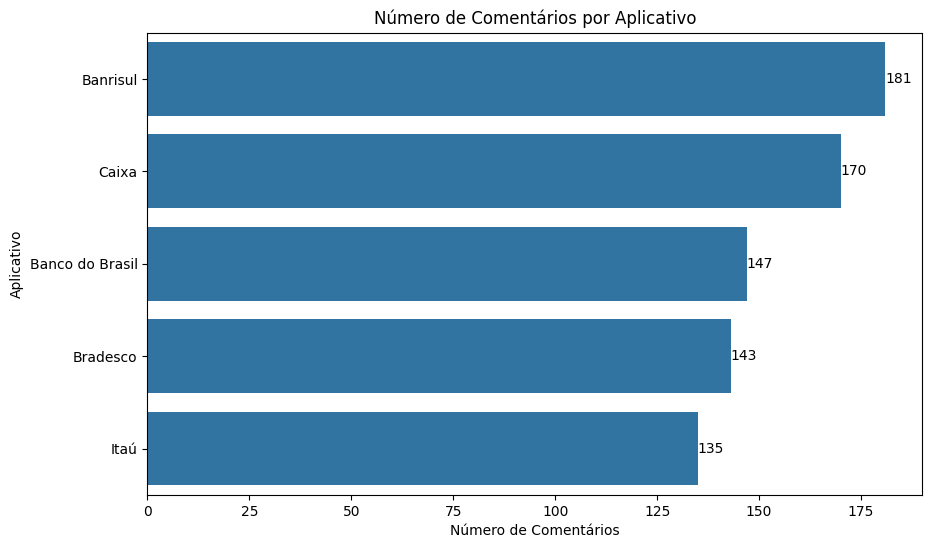

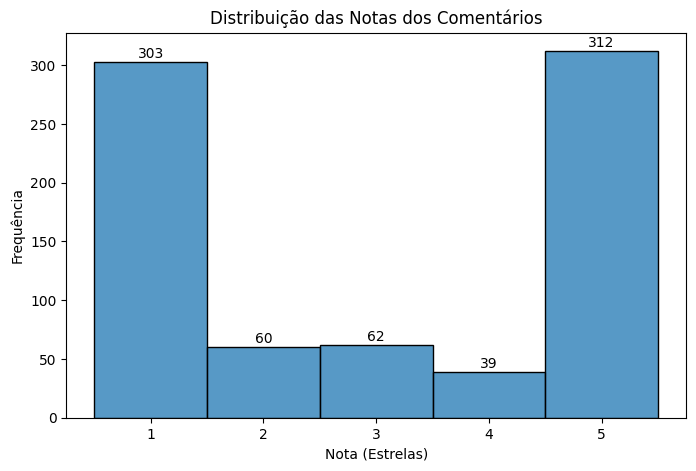

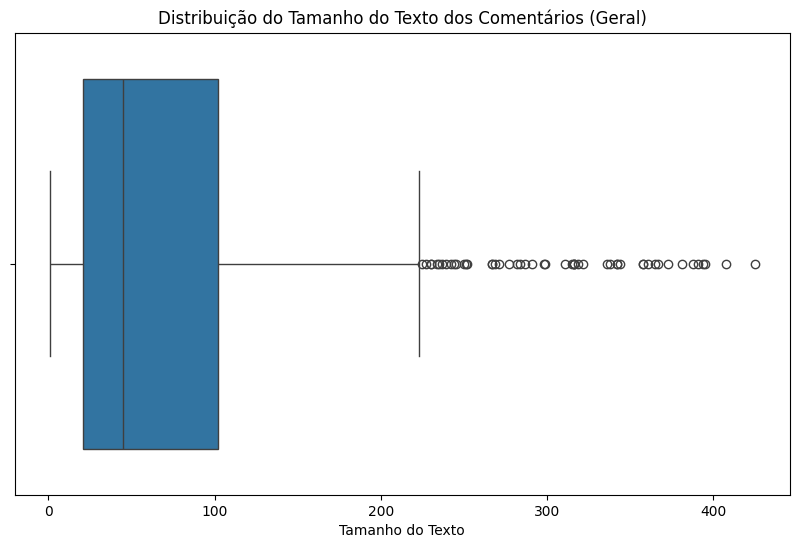

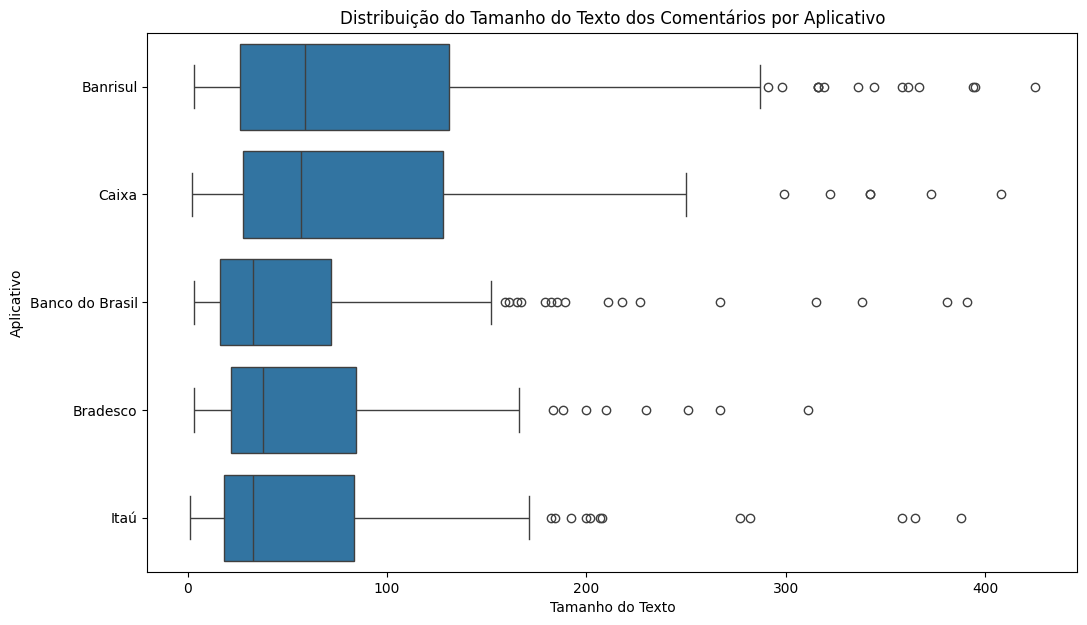

In [ ]:


# 1. Gráfico de barras por aplicativo
plt.figure(figsize=(10, 6))
ax = sns.countplot(data=df_limpo, y='appName', order=df_limpo['appName'].value_counts().index)
plt.title('Número de Comentários por Aplicativo')
plt.xlabel('Número de Comentários')
plt.ylabel('Aplicativo')

# Adicionar o número em cima de cada barra
for p in ax.patches:
    width = p.get_width()
    plt.text(width, p.get_y() + p.get_height() / 2,    # Posição do texto
             f'{int(width)}',                               # Formato do texto
             ha='left', va='center')                        # Alinhamento

plt.show()

# 2. Histograma por nota (estrelas)
plt.figure(figsize=(8, 5))
ax_hist = sns.histplot(data=df_limpo, x='score', bins=5, kde=False, discrete=True)
plt.title('Distribuição das Notas dos Comentários')
plt.xlabel('Nota (Estrelas)')
plt.ylabel('Frequência')
plt.xticks([1, 2, 3, 4, 5])

# Adicionar o número em cima de cada barra do histograma
for p in ax_hist.patches:
    height = p.get_height()
    if height > 0: # Only annotate bars with actual values
        ax_hist.annotate(f'{int(height)}',
                         (p.get_x() + p.get_width()/2, height-5),
                         ha='center', va='bottom',
                         xytext=(0, 5),
                         textcoords='offset points')

plt.show()

# 3. Boxplot por tamanho do texto (geral)
df_limpo['text_length'] = df_limpo['comentarios_limpos'].apply(len)
plt.figure(figsize=(10, 6))
sns.boxplot(data=df_limpo, x='text_length')
plt.title('Distribuição do Tamanho do Texto dos Comentários (Geral)')
plt.xlabel('Tamanho do Texto')
plt.show()

# 4. Boxplot por tamanho do texto (por aplicativo)
plt.figure(figsize=(12, 7))
sns.boxplot(data=df_limpo, x='text_length', y='appName', order=df_limpo['appName'].value_counts().index)
plt.title('Distribuição do Tamanho do Texto dos Comentários por Aplicativo')
plt.xlabel('Tamanho do Texto')
plt.ylabel('Aplicativo')
plt.show()

#### Análise dos gráficos

#### 1. Distribuição por Aplicativo

É perceptível a diferença na quantidade de análises por aplicativos, no caso específico do maior deles, o Banco Banrisul teve a maior contagem por conta de um menor número de problemas na etapa de limpeza de dados, pois houveram menos comentários "inválidos" (vazios, muito curtos e/ou apenas emojis). É possível observar também, pelo conteúdo destes, que houveram instabilidades no sistema de login, lentidão de acesso e problemas semelhantes.

#### 2. Distribuição por Notas

Houve uma quantidade maior de notas "1" e "5" na contagem geral. Parte significativa dessas contagens apareceu em junho de 2026, pelas mais variadas ocorrências de problemas nos aplicativos, esse evento não ficou apenas presente em um aplicativo, mas em todos de maneira geral.


#### 3. Distribuição Por tamanho do texto (BoxPlot) geral

O boxplot de comentários gerais mostra uma desproporção na dimensão dos textos encontrados. Os principais outiliers são os que excederam 500 caracteres e que podem conter criticas, relatórios de problemas e até elogios por dos usuários.

---

### 3.4 Palavras, termos e n-gramas frequentes
---


In [ ]:


def generate_ngrams(text, n):
    if not isinstance(text, str):
        return []

    # 1. Removemos a pontuação para que ela não crie N-gramas falsos (ex: "ruim !")
    text = text.translate(str.maketrans('', '', string.punctuation))

    # Como o texto já foi muito bem tratado, um simples split() já resolve a tokenização
    tokens = text.split()

    tokens = [word for word in tokens if word.isalnum()]

    if n == 1:
        return tokens
    else:
        return [' '.join(tokens[i:i+n]) for i in range(len(tokens) - n + 1)]

# Listas para guardar os resultados
unigrams = []
bigrams = []
trigrams = []

# Aplica a função no dataframe já limpo
for comment in df_limpo['comentarios_limpos']:
    unigrams.extend(generate_ngrams(comment, 1))
    bigrams.extend(generate_ngrams(comment, 2))
    trigrams.extend(generate_ngrams(comment, 3))

# Conta as frequências
top_unigrams = Counter(unigrams).most_common(10)
top_bigrams = Counter(bigrams).most_common(10)
top_trigrams = Counter(trigrams).most_common(10)

# Exibe os resultados
print("\n--- Top 10 Unigrams ---")
for word, count in top_unigrams:
    print(f"'{word}': {count}")

print("\n--- Top 10 Bigrams ---")
for phrase, count in top_bigrams:
    print(f"'{phrase}': {count}")

print("\n--- Top 10 Trigrams ---")
for phrase, count in top_trigrams:
    print(f"'{phrase}': {count}")


--- Top 10 Unigrams ---
'não': 451
'aplicativo': 432
'banco': 239
'conta': 124
'bom': 98
'consigo': 85
'fazer': 56
'abrir': 54
'abre': 48
'ótimo': 46

--- Top 10 Bigrams ---
'não consigo': 76
'aplicativo não': 40
'aplicativo banco': 33
'não abre': 31
'não conseguindo': 23
'abrir conta': 18
'não funciona': 16
'consigo acessar': 16
'aplicativo bom': 15
'toda hora': 15

--- Top 10 Trigrams ---
'não consigo acessar': 16
'aplicativo não abre': 7
'não consigo entrar': 7
'não consigo abrir': 7
'consigo acessar conta': 6
'não conseguindo abrir': 5
'pior aplicativo banco': 5
'aplicativo banco não': 5
'não conseguindo acessar': 5
'aplicativo fácil usar': 5


#### Considerações a cerca dos Ngramas

O unigrama mais frequente no dataset, é a palavra "não".
O bigrama mais frequente no dataset, é o "não consigo".

----

## Parte 4 – Representação textual


### 4.1 Baseline: TF-IDF

- Parâmetros: `max_features=...`, `ngram_range=(1,2)`, `min_df`, `max_df`  
- Dimensão da matriz resultante  

---

Apenas unigramas:

In [ ]:
tfidf_vect_uni = TfidfVectorizer(stop_words=palavras_irrelevantes, ngram_range=(1,1)) # apenas unigramas

tfidf_matrix_uni = tfidf_vect_uni.fit_transform(df_limpo['comentarios_limpos'])

tfidf_matrix_uni.shape

(776, 1915)

Temos 776 documentos (comentários) para um vocabulário de 1915 unigramas.

In [ ]:
# Obter top palavras chave de todo o corpus (feito com apoio da autocompleção da IA do Colab)

tfidf_matrix_uni_np = tfidf_matrix_uni.toarray()
top_words = tfidf_matrix_uni_np.sum(axis=0)
top_words_indices = top_words.argsort()[::-1]
top_words_values = top_words[top_words_indices]

top_words_df = pd.DataFrame({
    'Palavra': [tfidf_vect_uni.get_feature_names_out()[i] for i in top_words_indices],
    'TF-IDF': top_words_values
})

top_words_df

,Palavra,TF-IDF
0,aplicativo,55.633155
1,não,48.769103
2,bom,45.972485
3,banco,38.355723
4,ótimo,26.610706
...,...,...
1910,augusto,0.134675
1911,reclamarão,0.134675
1912,federais,0.134675
1913,começa,0.134675


Aqui, já vemos uma diferença na importância relativa a contagem direta dos termos. A palavra "app" se sobrepõe a "não" no score de importância usando TF-IDF.

---

Utilizando apenas bigramas:

In [ ]:
tfidf_vect_bi = TfidfVectorizer(stop_words=palavras_irrelevantes, ngram_range=(2,2)) # apenas bigramas

tfidf_matrix_bi = tfidf_vect_bi.fit_transform(df_limpo['comentarios_limpos'])

tfidf_matrix_bi.shape

(776, 5718)

É possível observar um aumento na dimensionalidade, tendo assim 5718 bigramas no seu vocabulário.

In [ ]:
# Obter top palavras chave de todo o corpus (feito com apoio da autocompleção da IA do Colab)

tfidf_matrix_bi_np = tfidf_matrix_bi.toarray()
top_words = tfidf_matrix_bi_np.sum(axis=0)
top_words_indices = top_words.argsort()[::-1]
top_words_values = top_words[top_words_indices]

top_words_df = pd.DataFrame({
    'Palavra': [tfidf_vect_bi.get_feature_names_out()[i] for i in top_words_indices],
    'TF-IDF': top_words_values
})

top_words_df


,Palavra,TF-IDF
0,não consigo,12.574108
1,ótimo aplicativo,9.191431
2,aplicativo não,7.781454
3,bom aplicativo,7.620678
4,aplicativo banco,7.108962
...,...,...
5713,bom funcionando,0.128170
5714,augusto ar,0.128170
5715,urgência reclamarão,0.128170
5716,processo advogados,0.128170


Aqui, temos mais contexto sobre os principais comentários, podendo observar que são tanto positivos quanto negativos.

---

Utilizando unigramas e bigramas:

In [ ]:
tfidf_vect_both = TfidfVectorizer(stop_words=palavras_irrelevantes, ngram_range=(1,2)) # unigramas e bigramas

tfidf_matrix_both = tfidf_vect_both.fit_transform(df_limpo['comentarios_limpos'])

tfidf_matrix_both.shape

(776, 7633)

Ou seja, temos 776 documentos (comentários) com um vocabulário de 7633 n-gramas, um aumento dos anteriores.

In [ ]:
# Obter top palavras chave de todo o corpus (feito com apoio da autocompleção da IA do Colab)

tfidf_matrix_both_np = tfidf_matrix_both.toarray()
top_words = tfidf_matrix_both_np.sum(axis=0)
top_words_indices = top_words.argsort()[::-1]
top_words_values = top_words[top_words_indices]

top_words_df = pd.DataFrame({
    'Palavra': [tfidf_vect_both.get_feature_names_out()[i] for i in top_words_indices],
    'TF-IDF': top_words_values
})

top_words_df


,Palavra,TF-IDF
0,aplicativo,34.595662
1,bom,33.560987
2,não,30.519582
3,banco,24.054661
4,ótimo,18.023702
...,...,...
7628,funcionar aplicativo,0.092844
7629,augusto,0.092844
7630,econômica paciência,0.092844
7631,neuma aba,0.092844


Aqui, voltamos ao padrão das unigramas, com palavras únicas sendo consideradas as principais. Perdemos um pouco de contexto e ganhamos dimensionalidade, porém para avaliar o real impacto, devemos avaliar as similaridades e realizar o agrupamento destes comentários.

---

### 4.2 Bag of Words (BoW)

- Utilizado como baseline adicional

---

Utilizando apenas unigramas:

In [ ]:

bow_vect_uni = CountVectorizer(stop_words=palavras_irrelevantes, ngram_range=(1,1))

bow_matrix_uni = bow_vect_uni.fit_transform(df_limpo['comentarios_limpos'])

bow_matrix_uni.shape

(776, 1915)

In [ ]:
# Obter top palavras chave de todo o corpus (feito com apoio da autocompleção da IA do Colab)

bow_matrix_uni_np = bow_matrix_uni.toarray()
top_words = bow_matrix_uni_np.sum(axis=0)
top_words_indices = top_words.argsort()[::-1]
top_words_values = top_words[top_words_indices]

top_words_df = pd.DataFrame({
    'Palavra': [bow_vect_uni.get_feature_names_out()[i] for i in top_words_indices],
    'BoW': top_words_values
})

top_words_df

,Palavra,BoW
0,não,451
1,aplicativo,432
2,banco,239
3,conta,124
4,bom,98
...,...,...
1910,leem,1
1911,leais,1
1912,line,1
1913,limões,1


Temos a mesma dimensionalidade que para TF-IDF, porém as palavras são diferentes, com "não" no topo da frequência.

---

Utilizando apenas bigramas:

In [ ]:
bow_vect_bi = CountVectorizer(stop_words=palavras_irrelevantes, ngram_range=(2,2))

bow_matrix_bi = bow_vect_bi.fit_transform(df_limpo['comentarios_limpos'])

bow_matrix_bi.shape

(776, 5718)

In [ ]:
# Obter top palavras chave de todo o corpus (feito com apoio da autocompleção da IA do Colab)

bow_matrix_bi_np = bow_matrix_bi.toarray()
top_words = bow_matrix_bi_np.sum(axis=0)
top_words_indices = top_words.argsort()[::-1]
top_words_values = top_words[top_words_indices]

top_words_df = pd.DataFrame({
    'Palavra': [bow_vect_bi.get_feature_names_out()[i] for i in top_words_indices],
    'BoW': top_words_values
})

top_words_df

,Palavra,BoW
0,não consigo,76
1,aplicativo não,40
2,aplicativo banco,33
3,não abre,31
4,não conseguindo,23
...,...,...
5713,não ia,1
5714,não indico,1
5715,não indo,1
5716,não instabilidade,1


Aqui sim, temos uma diferença significativa perante ao TF-IDF com bigramas. "não consigo" e "aplicativo não" figuram entre os termos com maior frequência.

---

Utilizando ambos:

In [ ]:
bow_vect_both = CountVectorizer(stop_words=palavras_irrelevantes, ngram_range=(1,2))

bow_matrix_both = bow_vect_both.fit_transform(df_limpo['comentarios_limpos'])

bow_matrix_both.shape

(776, 7633)

In [ ]:
# Obter top palavras chave de todo o corpus (feito com apoio da autocompleção da IA do Colab)

bow_matrix_both_np = bow_matrix_both.toarray()
top_words = bow_matrix_both_np.sum(axis=0)
top_words_indices = top_words.argsort()[::-1]
top_words_values = top_words[top_words_indices]

top_words_df = pd.DataFrame({
    'Palavra': [bow_vect_both.get_feature_names_out()[i] for i in top_words_indices],
    'BoW': top_words_values
})

top_words_df

,Palavra,BoW
0,não,451
1,aplicativo,432
2,banco,239
3,conta,124
4,bom,98
...,...,...
7628,menus parte,1
7629,menus não,1
7630,menu serviços,1
7631,menu,1


Em relação a dimensionalidade, temos resultados idênticos, porém com termos e contextos diferentes em relação ao TF-IDF.

---

### 4.3 Embeddings (SBERT / sentence-transformers)

- Modelo utilizado: `paraphrase-multilingual-mpnet-base-v2`  
- Dimensão do vetor gerado

---

Transformaremos os comentários em word embeddings através do modelo MPNet.

In [ ]:
# Vetorização por Embeddings com MPNet (feito com apoio da IA do Colab)


model = SentenceTransformer('paraphrase-multilingual-mpnet-base-v2')

embeddings = model.encode(df_limpo['comentarios_limpos'].tolist(), show_progress_bar=True)

embeddings.shape

modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/5.12k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/723 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.11G [00:00<?, ?B/s]

... (4 outputs left out)

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/25 [00:00<?, ?it/s]

(776, 768)

### 4.4 Comparação qualitativa/quantitativa

| Representação | Dimensionalidade | Tempo de processamento |
|---------------|------------------|------------------------|
| TF-IDF        | 7633             | 0.012s                 |
| BoW           | 7633             | 0.004s                 |
| SBERT         | 768              | 61.177s                |


---

In [1]:
# 1. Escolha o índice de um comentário de referência (feito com ajuda da IA)
idx_ref = 100
comentario_referencia = df_limpo['comentarios_limpos'].iloc[idx_ref]

print("="*60)
print(f"COMENTÁRIO DE REFERÊNCIA (Índice {idx_ref}):")
print(f"'{comentario_referencia}'")
print("="*60)

# Função para calcular e imprimir os Top 5 mais similares
def exibir_top_5_similares(matriz, df, idx_ref, nome_modelo, is_sparse=True):

    # Se for TF-IDF ou BoW (esparsas), precisamos usar matriz[idx_ref]
    # Se for BERT (densa/numpy array), usamos reshape(1, -1) para formato correto
    vetor_ref = matriz[idx_ref]
    if not is_sparse:
        vetor_ref = vetor_ref.reshape(1, -1)

    # Calcula a similaridade do cosseno entre o doc de referência e todo o resto do corpus
    similaridades = cosine_similarity(vetor_ref, matriz)[0]

    # Pega os índices ordenados do maior para o menor
    # Ignoramos o primeiro [::-1][1:6] pois o mais similar será ele mesmo (score 1.0)
    top_5_indices = similaridades.argsort()[::-1][1:6]

    print(f"\n---> Top 5 mais similares usando {nome_modelo}:")
    for i, idx in enumerate(top_5_indices, 1):
        score = similaridades[idx]
        texto = df['comentarios_limpos'].iloc[idx]
        print(f"{i}. (Score: {score:.4f}) | Índice {idx}: '{texto}'")

# Executando para as 3 representações
exibir_top_5_similares(bow_matrix_both, df_limpo, idx_ref, "Bag of Words (BoW)", is_sparse=True)
exibir_top_5_similares(tfidf_matrix_both, df_limpo, idx_ref, "TF-IDF", is_sparse=True)
exibir_top_5_similares(embeddings, df_limpo, idx_ref, "BERTimbau", is_sparse=False)

NameError: name 'df_limpo' is not defined

**1. Análise Quantitativa:**
* Observa-se que a representação em embeddings (SBERT) tende a gerar scores de similaridade médios mais elevados que os BoW e o TF-IDF. Como as matrizes de BoW e TF-IDF são altamente esparsas (a maioria das colunas é zero), comentários que não compartilham o exato mesmo vocabulário têm similaridade exata de 0.0. Já no SBERT, por operar em um espaço vetorial denso (768 dimensões), todas as frases possuem algum grau de proximidade no hiper-espaço, resultando em scores mais contínuos.

**2. Análise Qualitativa (Interpretação do Contexto):**
1. Bag of Words (BoW):

O BoW demonstrou ser uma representação puramente frequentista. Quantitativamente, ele costuma entregar scores mais altos que o TF-IDF, mas qualitativamente falha ao ignorar o contexto de negócio.

Ao buscar similares para o comentário “fatura não abre!”, o BoW priorizou frases genéricas que continham os termos "não" e "abre", ignorando completamente o núcleo do problema (a fatura).

Em comentários de desabafo longo (ex: “precisa crédito aqui não vai ter nada nem década uso”), o modelo se perdeu pareando palavras irrelevantes como "vai" e "nada", misturando problemas de login com reclamações sobre limites. O BoW atua como um buscador cego de caracteres, facilmente enganado por verbos e advérbios comuns.

2. TF-IDF:

O modelo TF-IDF apresentou o comportamento inverso. Devido à penalização do IDF sobre palavras onipresentes no domínio bancário (como "não", "app", "abre"), as matrizes geraram scores matemáticos esmagadoramente baixos (frequentemente abaixo de 0.20). No entanto, qualitativamente, ele foi muito mais inteligente que o BoW.

No caso do comentário sobre “crédito”, mesmo com um score de apenas 0.08, o TF-IDF foi o único modelo clássico a ignorar os verbos de desabafo e agrupar com sucesso outros clientes pedindo aumento de limite e cartões. Ele funciona como um excelente filtro de jargões técnicos, brilhando ao isolar o núcleo da reclamação.

3. SBERT:

A representação densa em 768 dimensões provou sua superioridade ao vencer tanto quantitativamente (scores altos consistentes) quanto qualitativamente, superando as principais barreiras da linguagem natural:

Variação Morfológica e de Nicho: Ao testar o comentário “não aparece limite cartão adicional dependente”, o SBERT ignorou a contagem exata e encontrou um "gêmeo semântico" que reclamava que “cartões adicionais ficaram todos misturados”. O modelo uniu os textos pela dor de negócio (gestão de dependentes), superando as flexões de plural/singular que quebram os modelos clássicos.

Ao analisar um relato longo de falha de pagamento via Pix no Uber, o SBERT não buscou a palavra "Uber", mas agrupou o texto a outros relatos longos de falhas complexas em jornadas de transação (como baixas de boletos).



## Parte 5 – Agrupamento dos comentários (etapa não supervisionada)

Nesta etapa, foi feito o clustering dos comentários para auxiliar na classificação em categorias.

### 5.1 Métodos testados

- **K-Means** com `k = 5, 7, 10, 12` (silhouette score)  
- **DBSCAN** / **HDBSCAN** (parâmetros `eps`, `min_samples`)  

---

#### 5.1.1 K-means

Normalizando:

In [ ]:
# Normalizando utilizando L2
from sklearn.preprocessing import normalize

embeddings_scaled = normalize(embeddings, norm='l2')

Descrição dos dados brutos:

In [ ]:

display(df_limpo.describe(include='all'))

,reviewId,content,score,thumbsUpCount,reviewCreatedVersion,at,replyContent,repliedAt,appVersion,appName,comentarios_limpos,text_length
count,776,776,776.000000,776.000000,666,776,688,688,666,776,776,776.000000
unique,776,776,NaN,NaN,36,772,452,668,36,5,755,NaN
top,1b6dbfaf-e04c-41f4-aa04-aa75d6010573,26 anos fiquei com esse banco e eles resolvera...,NaN,NaN,1.137.0.3,2026-06-25 11:55:29,Olá! Gostaríamos de entender melhor o que ocor...,2026-06-25 11:54:25,1.137.0.3,Banrisul,bom,NaN
freq,1,1,NaN,NaN,132,2,112,2,132,181,6,NaN
mean,NaN,NaN,2.996134,0.720361,NaN,NaN,NaN,NaN,NaN,NaN,NaN,75.860825
std,NaN,NaN,1.817119,12.888020,NaN,NaN,NaN,NaN,NaN,NaN,NaN,80.139402
min,NaN,NaN,1.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000
25%,NaN,NaN,1.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,21.000000
50%,NaN,NaN,3.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,45.000000
75%,NaN,NaN,5.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,102.250000


In [ ]:
# Agrupamento dos comentarios por kmeans (feito com apoio da IA do Colab)

kmeans = KMeans(n_clusters=6, random_state=42)
df_limpo['cluster_kmeans'] = kmeans.fit_predict(embeddings_scaled)

df_limpo[['cluster_kmeans', 'comentarios_limpos']]

,cluster_kmeans,comentarios_limpos
0,4,excelente aplicativo! ótimo manusear!
1,2,guri
2,3,"não conseguindo entrar smartphone aplicativo, ..."
3,1,aplicativo bom não acho opção acompanhar cartã...
4,2,não bom nova forma extrato.
...,...,...
771,5,ótimo aplicativo banco
772,1,boleto vezes paguei primeira parcela segunda t...
773,2,funciona facial lixo
774,1,"horrível. pior banco possível, ainda saiu oiti..."


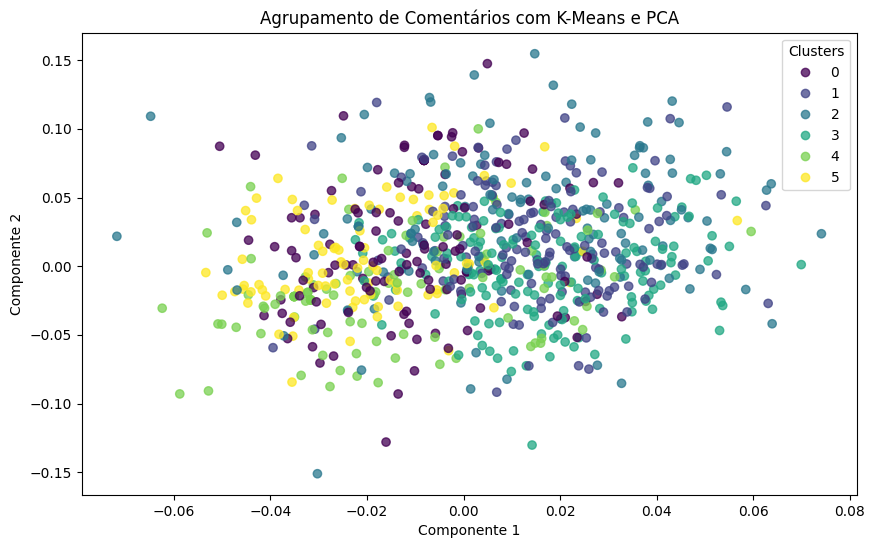

In [ ]:
plt.figure(figsize=(10, 6))
scatter = plt.scatter(embeddings_scaled[:, 0], embeddings_scaled[:, 1], c=df_limpo['cluster_kmeans'], alpha=0.75)
plt.title('Agrupamento de Comentários com K-Means e PCA')
plt.xlabel('Componente 1')
plt.ylabel('Componente 2')
plt.legend(*scatter.legend_elements(), title="Clusters")
plt.show()

#### 5.1.2 DBSCAN

Reduzindo dimensionalidade por UMAP

In [ ]:

umap_embeddings = UMAP(n_neighbors=30, n_components=2, min_dist=0.0, metric='cosine').fit_transform(embeddings_scaled)

In [ ]:

dbscan = DBSCAN(eps=0.55, min_samples=30)
df_limpo['cluster_dbscan'] = dbscan.fit_predict(umap_embeddings)

df_limpo[['cluster_dbscan', 'comentarios_limpos']]

,cluster_dbscan,comentarios_limpos
0,0,excelente aplicativo! ótimo manusear!
1,3,guri
2,1,"não conseguindo entrar smartphone aplicativo, ..."
3,1,aplicativo bom não acho opção acompanhar cartã...
4,3,não bom nova forma extrato.
...,...,...
771,4,ótimo aplicativo banco
772,1,boleto vezes paguei primeira parcela segunda t...
773,3,funciona facial lixo
774,1,"horrível. pior banco possível, ainda saiu oiti..."


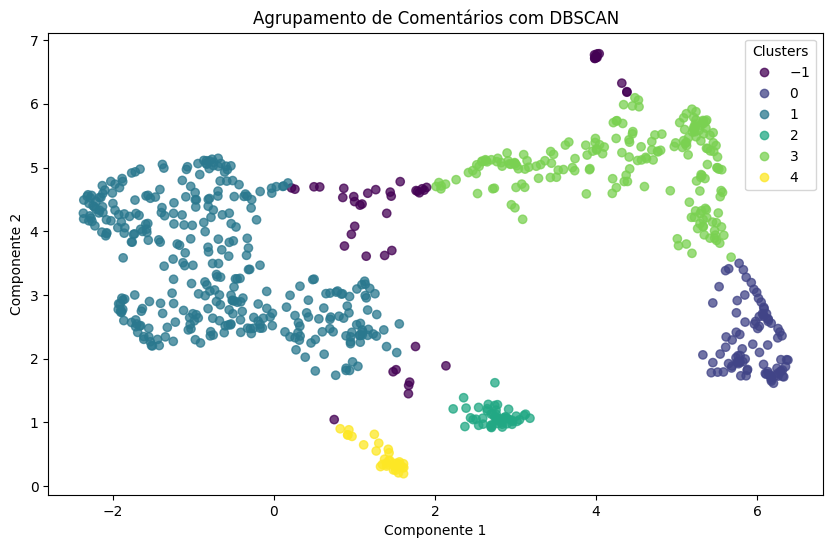

In [ ]:
plt.figure(figsize=(10, 6))
scatter = plt.scatter(umap_embeddings[:, 0], umap_embeddings[:, 1], c=df_limpo['cluster_dbscan'], alpha=0.75)
plt.title('Agrupamento de Comentários com DBSCAN')
plt.xlabel('Componente 1')
plt.ylabel('Componente 2')
plt.legend(*scatter.legend_elements(), title="Clusters")
plt.show()

---

#### 5.1.3 HDBSCAN

In [ ]:

hdbscan = HDBSCAN(min_cluster_size=30)
df_limpo['cluster_hdbscan'] = hdbscan.fit_predict(umap_embeddings)

df_limpo[['cluster_hdbscan', 'comentarios_limpos']]

,cluster_hdbscan,comentarios_limpos
0,0,excelente aplicativo! ótimo manusear!
1,0,guri
2,3,"não conseguindo entrar smartphone aplicativo, ..."
3,3,aplicativo bom não acho opção acompanhar cartã...
4,0,não bom nova forma extrato.
...,...,...
771,2,ótimo aplicativo banco
772,3,boleto vezes paguei primeira parcela segunda t...
773,0,funciona facial lixo
774,3,"horrível. pior banco possível, ainda saiu oiti..."


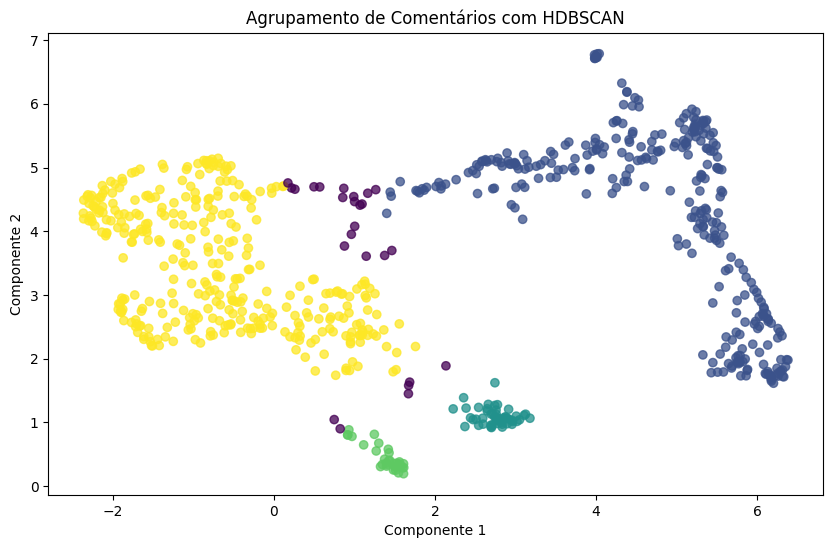

In [ ]:
plt.figure(figsize=(10, 6))
plt.scatter(umap_embeddings[:, 0], umap_embeddings[:, 1], c=df_limpo['cluster_hdbscan'], alpha=0.75)
plt.title('Agrupamento de Comentários com HDBSCAN')
plt.xlabel('Componente 1')
plt.ylabel('Componente 2')
plt.show()

### 5.2 Métricas de apoio

- Silhouette score médio para cada configuração  
- Inércia

---

Para KMeans:

Melhor Silhouette Score:  (2, np.float32(0.12692855))
Melhor K:  2
------------------------------------------------------------


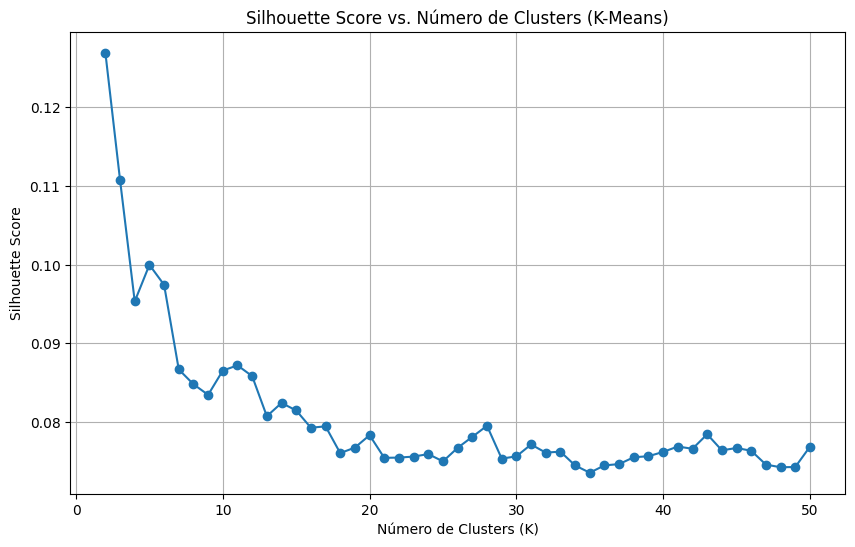

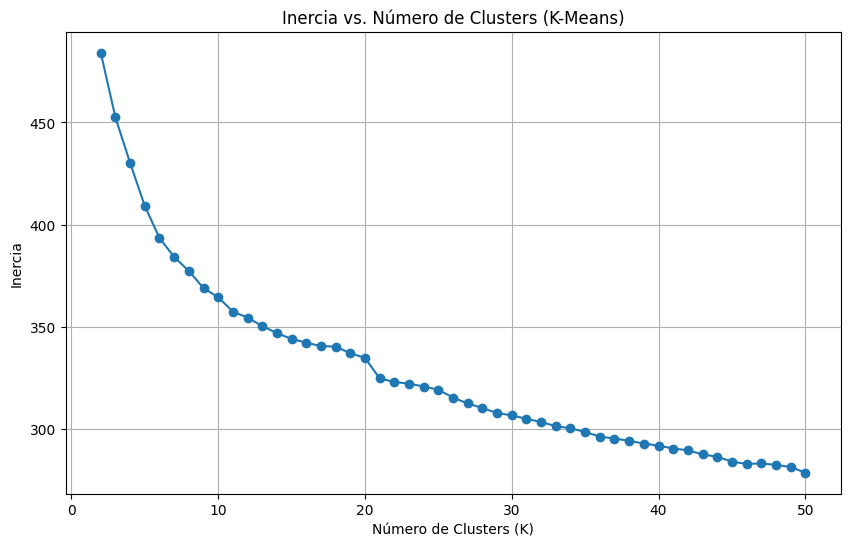

In [ ]:

kmeans_silhouette_scores = []
kmeans_inertia = []
kn = []

for k in range(2, 51):
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(embeddings_scaled)
    silhouette_avg = silhouette_score(embeddings_scaled, labels)
    kmeans_silhouette_scores.append((k, silhouette_avg))
    kmeans_inertia.append((k, kmeans.inertia_))
    kn.append(k)

print('Melhor Silhouette Score: ', max(kmeans_silhouette_scores, key=lambda x: x[1]))
print('Melhor K: ', max(kmeans_silhouette_scores, key=lambda x: x[1])[0])
print('--'*30)

plt.figure(figsize=(10, 6))
plt.plot(kn, [score for _, score in kmeans_silhouette_scores], marker='o')
plt.title('Silhouette Score vs. Número de Clusters (K-Means)')
plt.xlabel('Número de Clusters (K)')
plt.ylabel('Silhouette Score')
plt.grid()
plt.show()

plt.figure(figsize=(10, 6))
plt.plot(kn, [inertia for _, inertia in kmeans_inertia], marker='o')
plt.title('Inercia vs. Número de Clusters (K-Means)')
plt.xlabel('Número de Clusters (K)')
plt.ylabel('Inercia')
plt.grid()
plt.show()



---

Para DBSCAN:

In [ ]:
# Testando o parâmetro eps

for e in range(1, 100):
    e = e/100
    dbscan = DBSCAN(eps=e, min_samples=30)
    labels = dbscan.fit_predict(umap_embeddings)
    ruido = labels[labels == -1]
    clusters = unique(labels[labels != -1])
    print(f'eps: {e}, ruido: {len(ruido)}, clusters: {len(clusters)}')

eps: 0.01, ruido: 776, clusters: 0
eps: 0.02, ruido: 776, clusters: 0
eps: 0.03, ruido: 776, clusters: 0
eps: 0.04, ruido: 776, clusters: 0
eps: 0.05, ruido: 776, clusters: 0
eps: 0.06, ruido: 776, clusters: 0
eps: 0.07, ruido: 776, clusters: 0
eps: 0.08, ruido: 776, clusters: 0
eps: 0.09, ruido: 776, clusters: 0
eps: 0.1, ruido: 776, clusters: 0
eps: 0.11, ruido: 776, clusters: 0
eps: 0.12, ruido: 776, clusters: 0
eps: 0.13, ruido: 776, clusters: 0
eps: 0.14, ruido: 776, clusters: 0
eps: 0.15, ruido: 776, clusters: 0
eps: 0.16, ruido: 776, clusters: 0
eps: 0.17, ruido: 776, clusters: 0
eps: 0.18, ruido: 776, clusters: 0
eps: 0.19, ruido: 740, clusters: 1
eps: 0.2, ruido: 738, clusters: 1
eps: 0.21, ruido: 736, clusters: 1
eps: 0.22, ruido: 734, clusters: 1
eps: 0.23, ruido: 733, clusters: 1
eps: 0.24, ruido: 731, clusters: 1
eps: 0.25, ruido: 731, clusters: 1
eps: 0.26, ruido: 696, clusters: 2
eps: 0.27, ruido: 690, clusters: 2
eps: 0.28, ruido: 685, clusters: 2
eps: 0.29, ruido: 685,

O melhor parâmetro obtido foi epsilon de 0.6, para equilibrar número de clusters com menor ruído.

---

Para HDBSCAN:

In [ ]:
# Testando min_samples

for m in range(30, 100):
    hdbscan = HDBSCAN(min_cluster_size=m)
    labels = hdbscan.fit_predict(umap_embeddings)
    ruido = labels[labels == -1]
    rotulos = unique(labels[labels != -1])
    print(f'min_samples: {m}, ruido: {len(ruido)}, clusters: {len(rotulos)}')

min_samples: 30, ruido: 25, clusters: 4
min_samples: 31, ruido: 19, clusters: 4
min_samples: 32, ruido: 19, clusters: 4
min_samples: 33, ruido: 75, clusters: 4
min_samples: 34, ruido: 32, clusters: 3
min_samples: 35, ruido: 45, clusters: 3
min_samples: 36, ruido: 59, clusters: 3
min_samples: 37, ruido: 59, clusters: 3
min_samples: 38, ruido: 56, clusters: 3
min_samples: 39, ruido: 57, clusters: 3
min_samples: 40, ruido: 55, clusters: 3
min_samples: 41, ruido: 54, clusters: 3
min_samples: 42, ruido: 55, clusters: 3
min_samples: 43, ruido: 56, clusters: 3
min_samples: 44, ruido: 56, clusters: 3
min_samples: 45, ruido: 57, clusters: 3
min_samples: 46, ruido: 57, clusters: 3
min_samples: 47, ruido: 57, clusters: 3
min_samples: 48, ruido: 57, clusters: 3
min_samples: 49, ruido: 57, clusters: 3
min_samples: 50, ruido: 59, clusters: 3
min_samples: 51, ruido: 63, clusters: 3
min_samples: 52, ruido: 131, clusters: 3
min_samples: 53, ruido: 0, clusters: 2
min_samples: 54, ruido: 0, clusters: 2
m

### 5.3 Exemplos representativos por cluster

---

#### K-Means:

In [ ]:
# Amostras de cada cluster:

print('Representatividade de cada cluster: ')
print(df_limpo['cluster_kmeans'].value_counts())


df_limpo.groupby('cluster_kmeans')[['content', 'cluster_kmeans']].head(99999).sort_values(by='cluster_kmeans')

Representatividade de cada cluster: 
cluster_kmeans
3    171
1    155
2    133
0    123
4    101
5     93
Name: count, dtype: int64


,content,cluster_kmeans
22,sempre some a conexão!!!,0
24,gosto muito fo Banrisul,0
738,o melhor de todos,0
740,"está muito bom, mas fluído",0
750,ótimo gosto muito de usa,0
...,...,...
747,excelente eu gostei bastante de ser cliente do...,5
751,app fácil de usar sou cliente há mais de 15 an...,5
722,Amo atendimento desse banco!,5
771,ótimo app Itau,5


#### DBSCAN:

In [ ]:
# Amostras de cada cluster:

print('Representatividade de cada cluster: ')
print(df_limpo['cluster_dbscan'].value_counts())

df_limpo.groupby('cluster_dbscan')[['content', 'cluster_dbscan']].head(9999).sort_values(by='cluster_dbscan')

Representatividade de cada cluster: 
cluster_dbscan
 1    350
 3    199
 0     90
 2     52
-1     50
 4     35
Name: count, dtype: int64


,content,cluster_dbscan
770,meio confuso.... e não da pra entender a fatura,-1
762,👍 bom,-1
538,não consigo atualizar,-1
546,Muito bom,-1
518,pouca customizacao algumas coisas sao dificeis...,-1
...,...,...
98,Banco com fácil acesso a tua conta.Aplicativo ...,4
72,"Preciso do APP para conta poupança, este só ac...",4
751,app fácil de usar sou cliente há mais de 15 an...,4
26,muito bom aplicativo Banrisul 👍,4


#### HDBSCAN:

In [ ]:
# Amostras de cada cluster:
print('Representatividade de cada cluster: ')
print(df_limpo['cluster_hdbscan'].value_counts())


df_limpo.groupby('cluster_hdbscan').sample(n=10)[['content', 'cluster_hdbscan']]

Representatividade de cada cluster: 
cluster_hdbscan
 3    352
 0    313
 1     52
 2     34
-1     25
Name: count, dtype: int64


,content,cluster_hdbscan
403,quando faz pix falta deixar o valor de saldo d...,-1
608,por favor como fasso pra atualizar o meu site ...,-1
347,"antes de atualizar nunca tinha dado problema, ...",-1
378,"problema nos pix,nqo aparece pra confirmar fic...",-1
752,Essa atualização tá ruim,-1
380,Falar com alguém é difícil!!!! não consigo ace...,-1
390,"EU c/11.000,00 aplicados NÃO CONSIGO movimenta...",-1
5,Formato novo extrato office terrivel. voltem o...,-1
444,Ruim . Não consigo acessar .,-1
531,Não estou conseguindo atualizar Não estou cons...,-1


### 5.4 K-means com separação dos comentários por tamanho (VERSÃO FINAL UTILIZADA)

Para que os clusters de comentários longos sejam melhor separados, foi criada a abordagem com uma separação prévia dos mesmos, com o grupo df_curtos (menos de 4 termos), e df_longos (5 termos ou mais).


In [ ]:
# IA utilizada para formatação e ajuda com mapeamento de palavras em caixa alta


# Baixa as stopwords (apenas uma vez)
nltk.download('stopwords', quiet=True)
palavras_irrelevantes = stopwords.words('portuguese')

# 2. REMOVE as palavras de negação da lista de stopwords (Para não deletá-las)
palavras_irrelevantes.remove('não')
#palavras_irrelevantes.remove('nao')
palavras_irrelevantes.remove('nem')
#palavras_irrelevantes.remove('nunca')

palavras_irrelevantes.extend([
    'pra', 'pro', 'pras', 'pros',
    'q', 'tá', 'ta', 'vc', 'vcs',
    'pq', 'aí', 'lá', 'aplicativo', 'banco', 'app', 'pix'
])

# Inicializa o Enelvo
normalizador = Normaliser(tokenizer='readable', capitalize_inis=False,
                          capitalize_pns=False, capitalize_acs=False)

# ==========================================
# PIPELINE DE LIMPEZA
# ==========================================
def pipeline_nlp(texto):
    if not isinstance(texto, str):
        return ""

    texto_str = str(texto)
    tokens_originais = texto_str.split()

    # PASSO 1: Enelvo lê e normaliza a FRASE INTEIRA (tudo fica minúsculo)
    texto_norm = normalizador.normalise(texto_str)

    # PASSO 1.5: Curativo para as alucinações do Enelvo
    texto_norm = re.sub(r'\bnao\b', 'não', texto_norm)
    texto_norm = re.sub(r'\bappplication\b', 'aplicativo', texto_norm)
    texto_norm = re.sub(r'\bpia\b', 'pix', texto_norm)
    texto_norm = re.sub(r'\bbanco do brasil\b', 'banco', texto_norm)
    texto_norm = re.sub(r'\bBB\b', 'banco', texto_norm)
    texto_norm = re.sub(r'\bbb\b', 'banco', texto_norm)
    texto_norm = re.sub(r'\bcaixa\b', 'banco', texto_norm)
    texto_norm = re.sub(r'\bbanrisul\b', 'banco', texto_norm)
    texto_norm = re.sub(r'\bbradesco\b', 'banco', texto_norm)
    texto_norm = re.sub(r'\bitaú\b', 'banco', texto_norm)
    texto_norm = re.sub(r'\bitau\b', 'banco', texto_norm)
    texto_norm = re.sub(r'\bbanricompras\b', 'cartão', texto_norm)
    texto_norm = re.sub(r'\bmuuuitooo\b', 'muito', texto_norm)

    # PASSO 1.8: Mapeamento Retroativo de Caixa Alta (mantém a ênfase original)
    #for token in tokens_originais:
    #    token_limpo = re.sub(r'[^\w\s]', '', token)
    #    if token_limpo.isupper() and len(token_limpo) > 1:
    #        texto_norm = re.sub(rf'\b{re.escape(token_limpo.lower())}\b', token_limpo, texto_norm)

    # PASSO 2: Garante que as pontuações estão separadas por espaço
    texto_espacado = re.sub(r'([!?.,:;])', r' \1 ', texto_norm)

    # Tratamento de números
    texto_espacado = re.sub(r'\d+', '', texto_espacado)

    # PASSO 3: Remoção de Stopwords
    tokens = texto_espacado.split()
    tokens_filtrados = [
        token for token in tokens
        if token.lower() not in palavras_irrelevantes
    ]



    # PASSO 4: Remonta o texto limpo
    texto_final = " ".join(tokens_filtrados)
    texto_final = re.sub(r' ([!?.,:;])', r'\1', texto_final) # Cola a pontuação
    texto_final = re.sub(r'\s+', ' ', texto_final).strip()    # Remove espaços duplos

    return texto_final

# Aplica o pipeline consolidado no DataFrame limpo
df_limpo['comentarios_limpos'] = df_limpo['content'].apply(pipeline_nlp)

# 1. Contar o número de palavras após a limpeza
df_limpo['num_palavras'] = df_limpo['comentarios_limpos'].apply(lambda x: len(str(x).split()))

# 2. Definir um limite (threshold) - geralmente 4 ou 5 palavras funciona bem
limite_palavras = 4

# 3. Separar em dois DataFrames distintos
df_curtos = df_limpo[df_limpo['num_palavras'] <= limite_palavras].copy()
df_longos = df_limpo[df_limpo['num_palavras'] > limite_palavras].copy()

print(f"Total de comentários curtos: {len(df_curtos)}")
print(f"Total de comentários longos: {len(df_longos)}")

ERROR:enelvo.normaliser:Failed to normalise word "banricompras"!
ERROR:enelvo.normaliser:Failed to normalise word "banricompras"!


Total de comentários curtos: 340
Total de comentários longos: 436


In [ ]:
# Vetorização por Embeddings (Atualizado para Sentence-BERT)
from sentence_transformers import SentenceTransformer

# OPÇÃO 1: Multilíngue de altíssima performance (Recomendado)
model = SentenceTransformer('paraphrase-multilingual-mpnet-base-v2')

# OPÇÃO 2: Se o Colab estiver sem GPU ou estourando a RAM, use este que é mais leve:
# model = SentenceTransformer('paraphrase-multilingual-MiniLM-L12-v2')

# OPÇÃO 3: Específico para STS em Português (pode testar se quiser comparar)
# model = SentenceTransformer('rufimelo/bert-large-portuguese-cased-sts')

# Gera os embeddings (se você separou em df_longos, troque df_limpo por df_longos aqui)
embeddings_longos = model.encode(df_longos['comentarios_limpos'].tolist(), show_progress_bar=True)

print("Formato dos embeddings:", embeddings_longos.shape)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Batches:   0%|          | 0/14 [00:00<?, ?it/s]

Formato dos embeddings: (436, 768)


In [ ]:
embeddings_scaled_longos = normalize(embeddings_longos, norm='l2')

In [ ]:
# 3. Reduz a dimensionalidade para 2D (Para conseguir plotar no gráfico)
pca_longos = PCA(n_components=2)
embeddings_2d_longos = pca_longos.fit_transform(embeddings_scaled_longos)

# 4. Aplica o K-Means
kmeans_longos = KMeans(n_clusters=4, random_state=42)
df_longos['cluster_kmeans'] = kmeans_longos.fit_predict(embeddings_scaled_longos)

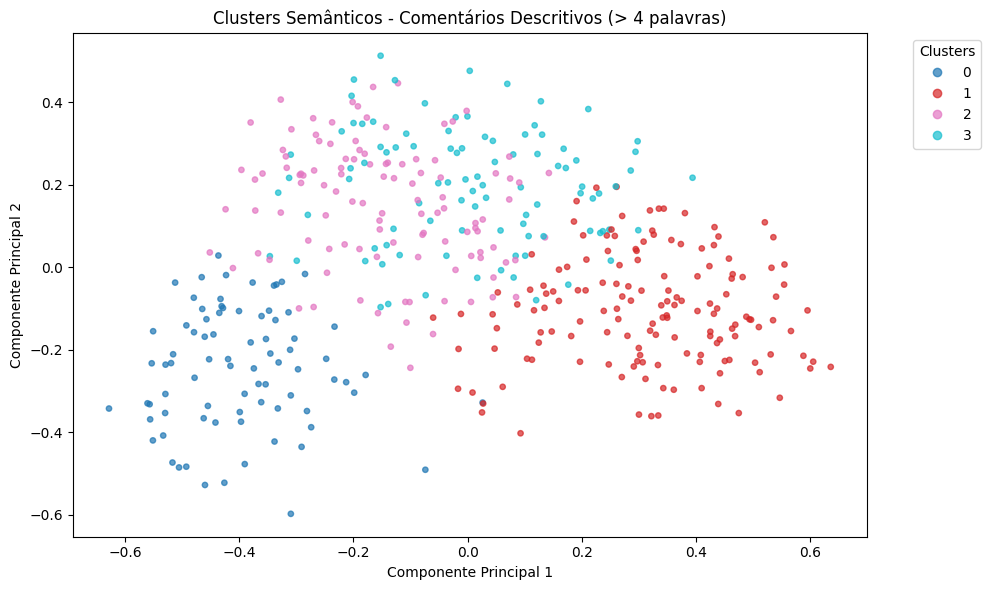

In [ ]:
# ==========================================
# 5. AQUI ENTRA A SUA ETAPA DE PLOTAGEM
# ==========================================
plt.figure(figsize=(10, 6))

# Observe que passamos as coordenadas 2D dos longos (X e Y) e as cores (c) baseadas nos clusters dos longos
scatter = plt.scatter(embeddings_2d_longos[:, 0],
                      embeddings_2d_longos[:, 1],
                      c=df_longos['cluster_kmeans'],
                      cmap='tab10', # tab10 é uma paleta de cores excelente para clusters
                      s=15,         # Tamanho dos pontos
                      alpha=0.7)    # Transparência para ver onde há sobreposição

plt.title('Clusters Semânticos - Comentários Descritivos (> 4 palavras)')
plt.xlabel('Componente Principal 1')
plt.ylabel('Componente Principal 2')

# A sua linha de legenda entra aqui, puxando os dados do scatter que acabamos de criar
plt.legend(*scatter.legend_elements(), title="Clusters", bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout() # Evita que a legenda fique cortada ao salvar a imagem
plt.show()

In [ ]:

embeddings_curtos = model.encode(df_curtos['comentarios_limpos'].tolist(), show_progress_bar=True)

print("Formato dos embeddings:", embeddings_curtos.shape)

Batches:   0%|          | 0/11 [00:00<?, ?it/s]

Formato dos embeddings: (340, 768)


In [ ]:
embeddings_scaled_curtos = normalize(embeddings_curtos, norm='l2')

In [ ]:
# 3. Reduz a dimensionalidade para 2D (Para conseguir plotar no gráfico)
pca_curtos = PCA(n_components=2)
embeddings_2d_curtos = pca_curtos.fit_transform(embeddings_scaled_curtos)

# 4. Aplica o K-Means
kmeans_curtos = KMeans(n_clusters=2, random_state=42)
df_curtos['cluster_kmeans'] = kmeans_curtos.fit_predict(embeddings_scaled_curtos)

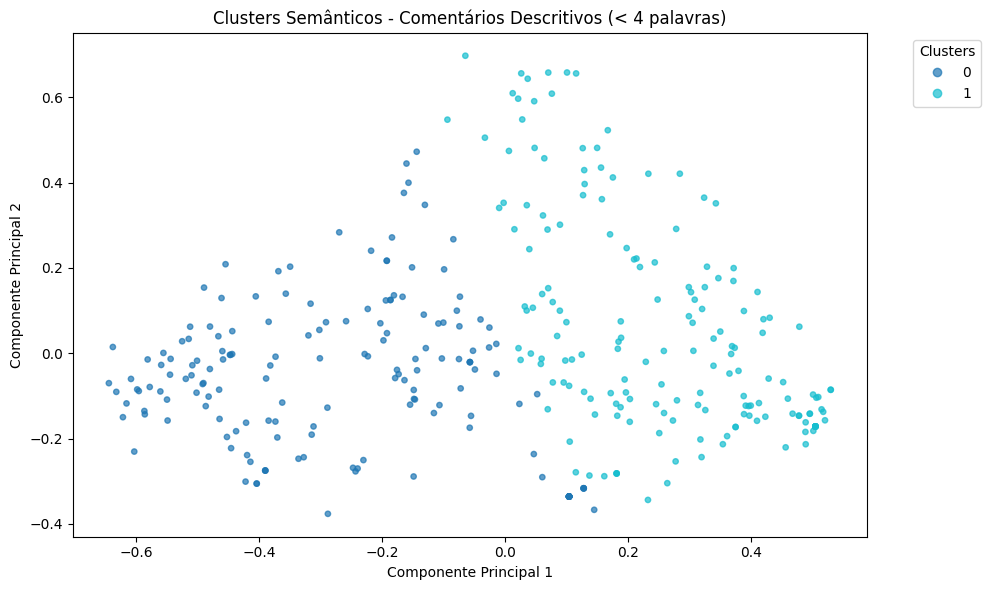

In [ ]:
# ==========================================
# 5.PLOTAGEM
# ==========================================
plt.figure(figsize=(10, 6))

scatter = plt.scatter(embeddings_2d_curtos[:, 0],
                      embeddings_2d_curtos[:, 1],
                      c=df_curtos['cluster_kmeans'],
                      cmap='tab10',
                      s=15,
                      alpha=0.7)

plt.title('Clusters Semânticos - Comentários Descritivos (< 4 palavras)')
plt.xlabel('Componente Principal 1')
plt.ylabel('Componente Principal 2')

plt.legend(*scatter.legend_elements(), title="Clusters", bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout() # Evita que a legenda fique cortada ao salvar a imagem
plt.show()

In [ ]:
# Amostras de cada cluster:

print('Representatividade de cada cluster: ')
print(df_curtos['cluster_kmeans'].value_counts())


df_curtos.groupby('cluster_kmeans')[['content', 'cluster_kmeans']].head(99999).sort_values(by='cluster_kmeans')

Representatividade de cada cluster: 
cluster_kmeans
1    173
0    167
Name: count, dtype: int64


,content,cluster_kmeans
773,funciona facial lixo,0
18,app horrível so da erro,0
17,terceira vez q abro conta,0
16,não estou conseguindo abrir meu aplicativo???,0
15,"muito lento,irritante",0
...,...,...
25,ótimo banco,1
26,muito bom aplicativo Banrisul 👍,1
762,👍 bom,1
0,Excelente aplicativo! Ótimo de manusear!,1


In [ ]:

# 1. Agrupa todos os textos de cada cluster em um único documento
docs_por_cluster = df_curtos.groupby('cluster_kmeans')['comentarios_limpos'].apply(' '.join).reset_index()

# 2. Remove o ruído (-1) e RESETA O ÍNDICE para alinhar com a matriz do TF-IDF
docs_por_cluster = docs_por_cluster[docs_por_cluster['cluster_kmeans'] != -1].reset_index(drop=True)

# 3. Aplica o TF-IDF
tfidf = TfidfVectorizer(max_df=0.9, min_df=1, ngram_range=(1, 2))
tfidf_matrix = tfidf.fit_transform(docs_por_cluster['comentarios_limpos'])
vocabulario = tfidf.get_feature_names_out()

# 4. Extrai as top 5 palavras de cada cluster
print("--- TOP PALAVRAS POR CLUSTER ---")
for i, row in docs_por_cluster.iterrows():
    cluster_id = row['cluster_kmeans']

    # Pega os scores TF-IDF desta linha (cluster)
    tfidf_scores = tfidf_matrix[i].toarray()[0]

    # Pega os índices das 5 palavras com maior score
    top_indices = tfidf_scores.argsort()[-5:][::-1]

    # Mapeia os índices para as palavras reais
    top_palavras = [vocabulario[idx] for idx in top_indices]

    print(f"Cluster {cluster_id}: {', '.join(top_palavras)}")

--- TOP PALAVRAS POR CLUSTER ---
Cluster 0: ruim, não consigo, horrível, dando, acessar
Cluster 1: ótimo, excelente, fácil, rápido, prático


In [ ]:
# Amostras de cada cluster:

print('Representatividade de cada cluster: ')
print(df_longos['cluster_kmeans'].value_counts())


df_longos.groupby('cluster_kmeans')[['content', 'cluster_kmeans']].head(99999).sort_values(by='cluster_kmeans')

Representatividade de cada cluster: 
cluster_kmeans
1    149
2    111
3     96
0     80
Name: count, dtype: int64


,content,cluster_kmeans
35,"O aplicativo ficou bem bonito, mas tem consumi...",0
715,"É um bom banco, agora seria perfeito se tivess...",0
704,"já saí fora muito tempo taxa de conta aberta, ...",0
699,Ótimo Serviço e Muito fácil de Verificar toda ...,0
64,"quero agradecer o banrisul ,pela renegociação ...",0
...,...,...
707,essa seven não serve de nada.foi descontado um...,3
706,tá dando falha em pagamento simples como Uber ...,3
724,se você precisa de crédito aqui você não vai t...,3
775,26 anos fiquei com esse banco e eles resolvera...,3


In [ ]:
# 1. Agrupa todos os textos de cada cluster em um único documento
docs_por_cluster = df_longos.groupby('cluster_kmeans')['comentarios_limpos'].apply(' '.join).reset_index()

# 2. Remove o ruído (-1) e RESETA O ÍNDICE para alinhar com a matriz do TF-IDF
docs_por_cluster = docs_por_cluster[docs_por_cluster['cluster_kmeans'] != -1].reset_index(drop=True)

# 3. Aplica o TF-IDF
tfidf = TfidfVectorizer(max_df=0.9, min_df=2, ngram_range=(1, 2))
tfidf_matrix = tfidf.fit_transform(docs_por_cluster['comentarios_limpos'])
vocabulario = tfidf.get_feature_names_out()

# 4. Extrai as top 5 palavras de cada cluster
print("--- TOP PALAVRAS POR CLUSTER ---")
for i, row in docs_por_cluster.iterrows():
    cluster_id = row['cluster_kmeans']

    # Pega os scores TF-IDF desta linha (cluster)
    tfidf_scores = tfidf_matrix[i].toarray()[0]

    # Pega os índices das 5 palavras com maior score
    top_indices = tfidf_scores.argsort()[-5:][::-1]

    # Mapeia os índices para as palavras reais
    top_palavras = [vocabulario[idx] for idx in top_indices]

    print(f"Cluster {cluster_id}: {', '.join(top_palavras)}")

--- TOP PALAVRAS POR CLUSTER ---
Cluster 0: ótimo, simples, prático, excelente, bebê
Cluster 1: acessar, erro, não abre, atualizar, consigo acessar
Cluster 2: pior, ruim, horrível, trava, péssimo
Cluster 3: pagar, crédito, pagamento, bancos, péssimo


In [ ]:
mapa_curtos = {
    0: 4,
    1: 5,
}

df_curtos['cluster_kmeans'] = df_curtos['cluster_kmeans'].map(mapa_curtos)

df_final_clusterizado = pd.concat([df_longos, df_curtos], ignore_index=True)

print("Distribuição Final dos Clusters (Longos e Curtos juntos):")
print(df_final_clusterizado['cluster_kmeans'].value_counts().sort_index())

Distribuição Final dos Clusters (Longos e Curtos juntos):
cluster_kmeans
0     80
1    149
2    111
3     96
4    167
5    173
Name: count, dtype: int64


In [ ]:
mapa_nomes = {

    0: 'Elogios Longos' ,
    1: 'Reclamações Longas' ,
    2: 'Problemas aplicativo' ,
    3: 'Problemas Bancários',
    4: 'Reclamações Curtos' ,
    5: 'Elogios Curtas' ,
}

df_final_clusterizado['cluster_kmeans'] = df_final_clusterizado['cluster_kmeans'].map(mapa_nomes)


In [ ]:
nome_do_arquivo = 'avaliacoes_bancos_clusterizadas.csv'
df_final_clusterizado.to_csv(shared_folder + nome_do_arquivo, index=False, encoding='utf-8-sig')

### 5.5 Discussão

Podemos observar, por meio de inspeção, que K-Means utilizando normalização por PCA e separação dos cometários por tamanho aparenta ter os resultados mais coerentes, com a temática dos comentários tendo maior similaridade semântica. Além disso, os dados aparentam estar melhor distribuídos entre classes.

Os clusters representam temas claros, porém com ruídos pontuais, principalmente nos comentários longos.

---

## Parte 6 – Interpretação dos clusters e criação das classes

### 6.1 Taxonomia final (5 clusters)


| Classe | Nome | Descrição | Nº de comentários |
|--------|------|-----------|----------------|
| 1      | Elogios Longos | Elogios com 4 palavras ou mais | 80 |
| 2      | Reclamações Longas | Reclamações com 4 palavras ou mais | 149 |
| 3      | Problemas aplicativo | Reclamações e relatos específicos aos aplicativos | 111  |
| 4      | Problemas Bancários | Reclamações e relatos que envolvam serviços do banco | 96  |
| 5      | Elogios Curtos | Elogios com menos de 4 palavras | 167 |
| 6      | Reclamações Curtas | Reclamações com menos de 4 palavras | 173 |

---

Além da avaliação manual dos autores, foram verificados os uni/bigramas com maior ocorrência utilizando técnica TF-IDF, os quais auxiliaram na verificação e decisão pra nomenclatura final dos clusters.

### 6.2 Validação da coerência

- Clusters misturados foram reavaliados e ajustados manualmente

---

In [ ]:
# 1. Defina o caminho do arquivo
caminho_arquivo = shared_folder + 'avaliacoes_bancos_clusterizadas.csv'

# 2. Leia o CSV, transformando-o em um DataFrame do pandas
df_com_ruido = pd.read_csv(caminho_arquivo)

# 3. Agora sim, selecione as colunas desejadas
df_com_ruido[['cluster_kmeans', 'content']]

,cluster_kmeans,content
0,Reclamações Longas,Não estou conseguindo entrar pelo meu smartpho...
1,Problemas Bancários,o aplicativo e muito bom só n acho a opção de ...
2,Problemas aplicativo,Não está bom a nova forma do extrato.
3,Problemas aplicativo,Formato novo extrato office terrivel. voltem o...
4,Problemas Bancários,NAO RECOMENDO ESTE BANCO TAXAS ABSURDAS MUITA ...
...,...,...
771,Elogios Curtas,"Amei, bom demais."
772,Reclamações Curtos,muito ruim
773,Reclamações Curtos,mas ou menos
774,Elogios Curtas,ótimo app Itau


## Parte 7 – Rotulagem final da base

- Cada comentário recebeu um rótulo da taxonomia.  
- Rótulos baseados nos clusters, mas validados por leitura humana.  

---

Como haviam muitos ruídos, foi necessário editar alguns rótulos para realizar a correção. O arquivo final é 'avaliacoes_bancos_clusterizadas_corrigido.csv'.

In [ ]:
df_sem_ruido = pd.read_csv(shared_folder + 'avaliacoes_bancos_clusterizadas_corrigido.csv')

df_sem_ruido[df_sem_ruido['cluster_final'] == 'Elogios Curtos'] = 'Elogios Curtas'

/tmp/ipykernel_13246/1533431312.py:3: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'Elogios Curtas' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  df_sem_ruido[df_sem_ruido['cluster_final'] == 'Elogios Curtos'] = 'Elogios Curtas'
/tmp/ipykernel_13246/1533431312.py:3: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'Elogios Curtas' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  df_sem_ruido[df_sem_ruido['cluster_final'] == 'Elogios Curtos'] = 'Elogios Curtas'
/tmp/ipykernel_13246/1533431312.py:3: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'Elogios Curtas' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  df_sem_ruido[df_se

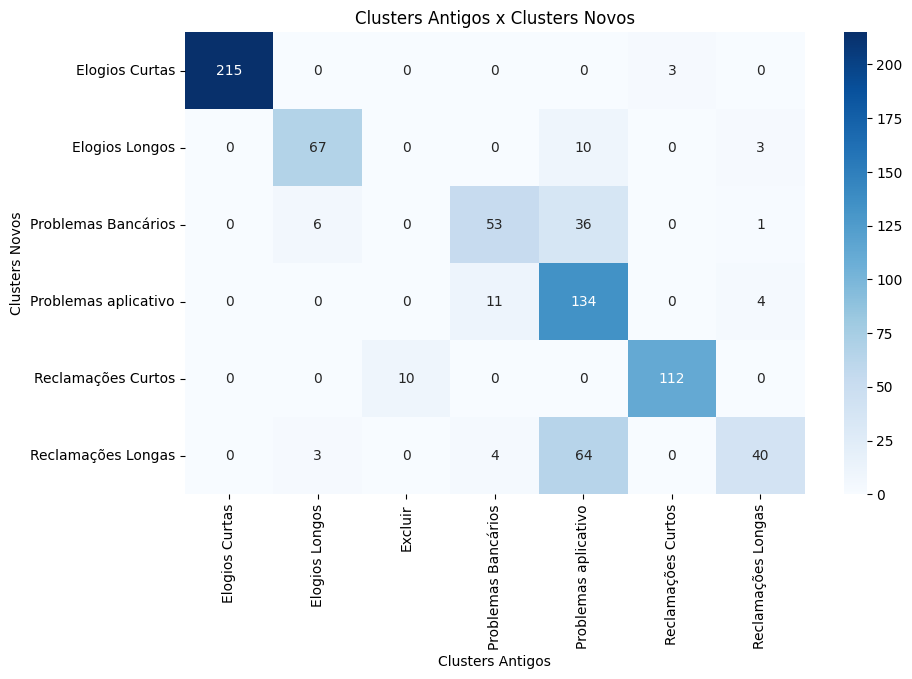

In [ ]:
# Heatmap dos clusters antigos e novos

plt.figure(figsize=(10, 6))
sns.heatmap(pd.crosstab(df_sem_ruido['cluster_kmeans'], df_sem_ruido['cluster_final']), annot=True, fmt='d', cmap='Blues')
plt.title('Clusters Antigos x Clusters Novos')
plt.xlabel('Clusters Novos')
plt.ylabel('Clusters Antigos')
plt.show()

Aqui, podemos observar que tivemos várias recategorizações, principalmente para os casos de 'Reclamações Longas', que por vezes era muito generalista.

In [ ]:
df_final = df_sem_ruido[df_sem_ruido['cluster_final'] != 'Excluir'] # Excluindo linhas sem informações relevantes no corpo

In [ ]:
df_final.to_csv(shared_folder + 'avaliacoes_bancos_clusterizadas_final.csv', index=False, encoding='utf-8-sig')

## Parte 8 – Classificação (etapa supervisionada)

### 8.1 Algoritmos treinados

- Regressão Logística  
- Naive Bayes (MultinomialNB)  
- Random Forest   

---

#### 8.1.1 Importações para classificação

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score, precision_score, recall_score
import matplotlib.pyplot as plt
import seaborn as sns

#### 8.1.2 Importações do CSV

In [ ]:
# Caminho do arquivo
caminho_arquivo = shared_folder + 'avaliacoes_bancos_clusterizadas_final.csv'
df = pd.read_csv(caminho_arquivo)

# Verifique as colunas
print(df[['cluster_final', 'content']].head())
print(f"Quantas amostras? {len(df)}")
print(f"Distribuição dos clusters:\n{df['cluster_final'].value_counts()}")

    cluster_final                                   content
0  Elogios Curtas  Excelente aplicativo! Ótimo de manusear!
1  Elogios Curtas                          ótimo aplicativo
2  Elogios Curtas                  sempre some a conexão!!!
3  Elogios Curtas                Excelente banco, parabéns.
4  Elogios Curtas                   gosto muito fo Banrisul
Quantas amostras? 766
Distribuição dos clusters:
cluster_final
Problemas aplicativo    244
Elogios Curtas          215
Reclamações Curtos      115
Elogios Longos           76
Problemas Bancários      68
Reclamações Longas       48
Name: count, dtype: int64


### 8.2 Separação treino/teste

- `train_test_split` com estratificação por classe (80/20 ou 70/30)  
- (Opcional) Validação cruzada com 5 folds

---

In [ ]:
X = df['comentarios_limpos']          # textos
y = df['cluster_final']   # rótulos (numéricos, ex: 0,1,2,...)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,          # 80% treino, 20% teste
    random_state=42,
    stratify=y     lass_weight='balance         # mantém proporção das classes
)

print(f"Treino: {len(X_train)} amostras, Teste: {len(X_test)} amostras")

Treino: 612 amostras, Teste: 154 amostras


In [ ]:
def avaliar_modelo(modelo, X_test, y_test, nome_modelo='Modelo'):
    y_pred = modelo.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    f1_macro = f1_score(y_test, y_pred, average='macro')
    prec_macro = precision_score(y_test, y_pred, average='macro')
    rec_macro = recall_score(y_test, y_pred, average='macro')

    print(f"\n--- {nome_modelo} ---")
    print(f"Acurácia: {acc:.4f}")
    print(f"F1-macro: {f1_macro:.4f}")
    print(f"Precisão (macro): {prec_macro:.4f}")
    print(f"Recall (macro): {rec_macro:.4f}")
    print("\nRelatório de classificação:\n", classification_report(y_test, y_pred))

    return {
        'Modelo': nome_modelo,
        'Acurácia': acc,
        'F1-macro': f1_macro,
        'Precisão (macro)': prec_macro,
        'Recall (macro)': rec_macro
    }

#### 8.2.1 TF‑IDF (para Regressão Logística e Random Forest)

In [ ]:
tfidf = TfidfVectorizer(
    #max_features=5000,        # opcional: limite de palavras
    stop_words=palavras_irrelevantes,     # se os textos estiverem em inglês; remova ou adapte para português
    ngram_range=(1, 2)        # unigramas + bigramas
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

#### 8.2.2 Bag of Words (para Naive Bayes – MultinomialNB espera contagens, não TF‑IDF)

In [ ]:
count_vec = CountVectorizer(
    #max_features=5000,
    stop_words=palavras_irrelevantes,
    ngram_range=(1, 2)
)

X_train_count = count_vec.fit_transform(X_train)
X_test_count = count_vec.transform(X_test)

#### 8.2.3 Embeddings (para Regressão Logística, Random Forest e Naive Bayes)

In [ ]:
# ==========================================
# 1. PREPARAÇÃO DOS TEXTOS
# ==========================================
X_textos = df['comentarios_limpos'].tolist()
y = df['cluster_final']

# ==========================================
# 2. GERAÇÃO DOS EMBEDDINGS
# ==========================================
model = SentenceTransformer('paraphrase-multilingual-mpnet-base-v2')

X_embeddings = model.encode(X_textos, show_progress_bar=True)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Batches:   0%|          | 0/24 [00:00<?, ?it/s]

In [ ]:
# ==========================================
# 3. DIVISÃO EM TREINO E TESTE (Corrigido)
# ==========================================
X_train_emb, X_test_emb, y_train, y_test = train_test_split(
    X_embeddings, y,
    test_size=0.2,          # 80% treino, 20% teste
    random_state=42,
    stratify=y              # mantém proporção das classes
)

print(f"Treino: {len(X_train_emb)} amostras, Teste: {len(X_test_emb)} amostras")

Treino: 612 amostras, Teste: 154 amostras


### 8.3 Treinamento e avaliação dos modelos

##### 8.3.1 Regressão Logística (com TF‑IDF)

In [ ]:
logreg = LogisticRegression(
    max_iter=1000,
    random_state=42,
    class_weight='balanced'   # útil se houver desbalanceamento
)

stratified_kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Validação cruzada nos dados de treino (opcional)
cv_scores = cross_val_score(logreg, X_train_tfidf, y_train, cv=stratified_kfold, scoring='accuracy')
print(f"CV (5 folds) - Regressão Logística: {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})")

# Treina com todo o treino
logreg.fit(X_train_tfidf, y_train)

# Avalia no teste
res_logreg = avaliar_modelo(logreg, X_test_tfidf, y_test, 'Regressão Logística (TF-IDF)')

CV (5 folds) - Regressão Logística: 0.5915 (+/- 0.0484)

--- Regressão Logística (TF-IDF) ---
Acurácia: 0.6494
F1-macro: 0.5336
Precisão (macro): 0.5766
Recall (macro): 0.5201

Relatório de classificação:
                       precision    recall  f1-score   support

      Elogios Curtas       0.84      0.72      0.78        43
      Elogios Longos       0.28      0.33      0.30        15
 Problemas Bancários       0.62      0.36      0.45        14
Problemas aplicativo       0.67      0.86      0.75        49
  Reclamações Curtos       0.65      0.65      0.65        23
  Reclamações Longas       0.40      0.20      0.27        10

            accuracy                           0.65       154
           macro avg       0.58      0.52      0.53       154
        weighted avg       0.65      0.65      0.64       154



##### 8.3.2 Naive Bayes (MultinomialNB) – usando Bag of Words

In [ ]:
nb = MultinomialNB(alpha=1.0)  # suavização de Laplace

cv_scores_nb = cross_val_score(nb, X_train_count, y_train, cv=stratified_kfold, scoring='accuracy')
print(f"CV (5 folds) - Naive Bayes: {cv_scores_nb.mean():.4f} (+/- {cv_scores_nb.std():.4f})")

nb.fit(X_train_count, y_train)
res_nb = avaliar_modelo(nb, X_test_count, y_test, 'Naive Bayes (BoW)')

CV (5 folds) - Naive Bayes: 0.5752 (+/- 0.0367)

--- Naive Bayes (BoW) ---
Acurácia: 0.5844
F1-macro: 0.3399
Precisão (macro): 0.6393
Recall (macro): 0.3603

Relatório de classificação:
                       precision    recall  f1-score   support

      Elogios Curtas       0.88      0.84      0.86        43
      Elogios Longos       0.50      0.07      0.12        15
 Problemas Bancários       1.00      0.21      0.35        14
Problemas aplicativo       0.46      1.00      0.63        49
  Reclamações Curtos       1.00      0.04      0.08        23
  Reclamações Longas       0.00      0.00      0.00        10

            accuracy                           0.58       154
           macro avg       0.64      0.36      0.34       154
        weighted avg       0.68      0.58      0.50       154



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/m

##### 8.3.3 Random Forest (com TF‑IDF)

In [ ]:
rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight='balanced'
)

cv_scores_rf = cross_val_score(rf, X_train_tfidf, y_train, cv=stratified_kfold, scoring='accuracy')
print(f"CV (5 folds) - Random Forest: {cv_scores_rf.mean():.4f} (+/- {cv_scores_rf.std():.4f})")

rf.fit(X_train_tfidf, y_train)
res_rf = avaliar_modelo(rf, X_test_tfidf, y_test, 'Random Forest (TF-IDF)')

CV (5 folds) - Random Forest: 0.6226 (+/- 0.0378)

--- Random Forest (TF-IDF) ---
Acurácia: 0.6104
F1-macro: 0.3422
Precisão (macro): 0.3062
Recall (macro): 0.3978

Relatório de classificação:
                       precision    recall  f1-score   support

      Elogios Curtas       0.58      1.00      0.74        43
      Elogios Longos       0.00      0.00      0.00        15
 Problemas Bancários       0.00      0.00      0.00        14
Problemas aplicativo       0.68      0.73      0.71        49
  Reclamações Curtos       0.58      0.65      0.61        23
  Reclamações Longas       0.00      0.00      0.00        10

            accuracy                           0.61       154
           macro avg       0.31      0.40      0.34       154
        weighted avg       0.46      0.61      0.52       154



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/m

##### 8.3.4 Regressão Logística (com Sentence-BERT)

---



Executando Validação Cruzada (5 folds) nos dados de treino...
Resultado CV (Accuracy): 0.7499 (+/- 0.0383)

Treinando o modelo definitivo de Regressão Logística...

--- RELATÓRIO DE CLASSIFICAÇÃO (DADOS DE TESTE) ---

--- Regressão Logística (SBERT) ---
Acurácia: 0.7857
F1-macro: 0.7228
Precisão (macro): 0.7114
Recall (macro): 0.7431

Relatório de classificação:
                       precision    recall  f1-score   support

      Elogios Curtas       0.93      0.91      0.92        43
      Elogios Longos       0.65      0.73      0.69        15
 Problemas Bancários       0.67      0.71      0.69        14
Problemas aplicativo       0.90      0.73      0.81        49
  Reclamações Curtos       0.77      0.87      0.82        23
  Reclamações Longas       0.36      0.50      0.42        10

            accuracy                           0.79       154
           macro avg       0.71      0.74      0.72       154
        weighted avg       0.81      0.79      0.79       154



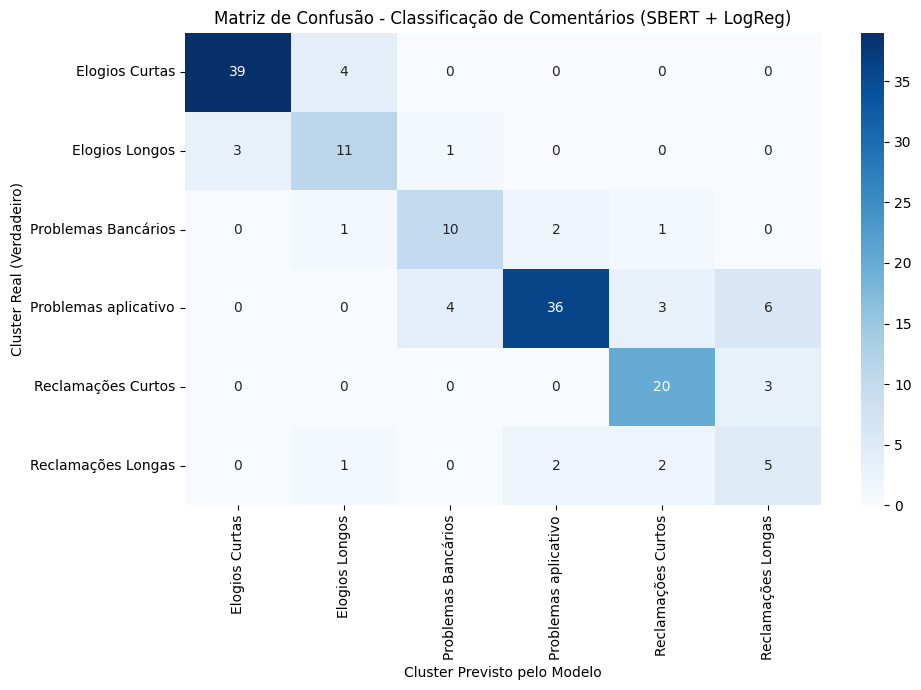

In [ ]:

modelo_lr = LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced')
# ==========================================
# 4. VALIDAÇÃO CRUZADA
# ==========================================
print("Executando Validação Cruzada (5 folds) nos dados de treino...")
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
balanced'
cv_scores = cross_val_score(modelo_lr, X_train_emb, y_train, cv=skf, scoring='accuracy')
print(f"Resultado CV (Accuracy): {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})")

# ==========================================
# 5. TREINAMENTO FINAL DO MODELO
# ==========================================
print("\nTreinando o modelo definitivo de Regressão Logística...")
modelo_lr.fit(X_train_emb, y_train)

# ==========================================
# 6. PREVISÃO E RESULTADOS
# ==========================================
y_pred = modelo_lr.predict(X_test_emb)

print("\n--- RELATÓRIO DE CLASSIFICAÇÃO (DADOS DE TESTE) ---")
#print(classification_report(y_test, y_pred))

res_lrbert = avaliar_modelo(modelo_lr, X_test_emb, y_test, 'Regressão Logística (SBERT)')

# Matriz de Confusão
plt.figure(figsize=(10, 7))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=sorted(y.unique()),
            yticklabels=sorted(y.unique()))
plt.title('Matriz de Confusão - Classificação de Comentários (SBERT + LogReg)')
plt.ylabel('Cluster Real (Verdadeiro)')
plt.xlabel('Cluster Previsto pelo Modelo')
plt.tight_layout()
plt.show()

##### 8.3.5 Random Forest (com Sentence-BERT)

---



Resultado CV (Accuracy): 0.7108 (+/- 0.0235)
Treinando o modelo Random Forest com Embeddings (isso pode levar alguns segundos)...

--- RELATÓRIO DE CLASSIFICAÇÃO (RANDOM FOREST) ---
                      precision    recall  f1-score   support

      Elogios Curtas       0.85      0.93      0.89        43
      Elogios Longos       0.62      0.33      0.43        15
 Problemas Bancários       1.00      0.29      0.44        14
Problemas aplicativo       0.59      0.92      0.72        49
  Reclamações Curtos       0.74      0.61      0.67        23
  Reclamações Longas       0.00      0.00      0.00        10

            accuracy                           0.70       154
           macro avg       0.63      0.51      0.53       154
        weighted avg       0.69      0.70      0.66       154


--- Random Forest (SBERT) ---
Acurácia: 0.7013
F1-macro: 0.5258
Precisão (macro): 0.6342
Recall (macro): 0.5127

Relatório de classificação:
                       precision    recall  f1-score 

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/m

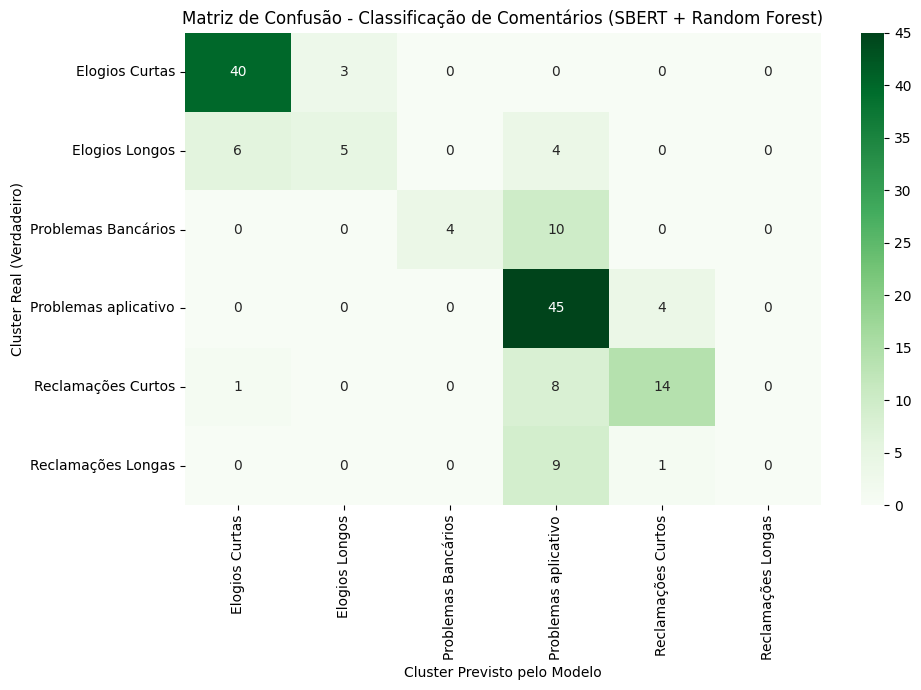

In [ ]:
modelo_rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight='balanced'
    #n_jobs=-1
)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Utilizando f1_macro para manter a consistência com a métrica de avaliação principal
cv_scores_rf = cross_val_score(modelo_rf, X_train_emb, y_train, cv=skf, scoring='accuracy')
print(f"Resultado CV (Accuracy): {cv_scores_rf.mean():.4f} (+/- {cv_scores_rf.std():.4f})")

print("Treinando o modelo Random Forest com Embeddings (isso pode levar alguns segundos)...")
modelo_rf.fit(X_train_emb, y_train)

# ==========================================
# 2. PREVISÃO NO CONJUNTO DE TESTE
# ==========================================
y_pred_rf = modelo_rf.predict(X_test_emb)

# ==========================================
# 3. MÉTRICAS DE DESEMPENHO
# ==========================================
print("\n--- RELATÓRIO DE CLASSIFICAÇÃO (RANDOM FOREST) ---")
print(classification_report(y_test, y_pred_rf))

res_rfbert = avaliar_modelo(modelo_rf, X_test_emb, y_test, 'Random Forest (SBERT)')

# ==========================================
# 4. MATRIZ DE CONFUSÃO
# ==========================================
plt.figure(figsize=(10, 7))
cm_rf = confusion_matrix(y_test, y_pred_rf)

sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Greens',
            xticklabels=sorted(y.unique()),
            yticklabels=sorted(y.unique()))

plt.title('Matriz de Confusão - Classificação de Comentários (SBERT + Random Forest)')
plt.ylabel('Cluster Real (Verdadeiro)')
plt.xlabel('Cluster Previsto pelo Modelo')
plt.tight_layout()
plt.show()

##### 8.3.6 Naive Bayes (com Sentence-BERT)

---



In [ ]:
from sklearn.naive_bayes import GaussianNB, MultinomialNB, ComplementNB
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import StratifiedKFold, cross_val_score

# =====================================================================
# CENÁRIO: Naive Bayes + BERTimbau (Embeddings Longos + Curtos)
# =====================================================================

print("\n" + "="*60)
print("TREINANDO NAIVE BAYES COM EMBEDDINGS COMBINADOS DO BERT")
print("="*60)

# Configurando o StratifiedKFold para manter o padrão rigoroso do projeto
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# ---------------------------------------------------------------------
# Opção 1: GaussianNB (aceita valores negativos - mais direto)
# ---------------------------------------------------------------------
gnb_model = GaussianNB()

print("Executando Validação Cruzada (5 folds) no GaussianNB...")
cv_scores_gnb = cross_val_score(gnb_model, X_train_emb, y_train, cv=skf, scoring='accuracy')
print(f"Resultado CV GaussianNB (Accuracy): {cv_scores_gnb.mean():.4f} (+/- {cv_scores_gnb.std():.4f})\n")

# Treina com todo o treino
gnb_model.fit(X_train_emb, y_train)
res_gnb = avaliar_modelo(gnb_model, X_test_emb, y_test, nome_modelo='NB Gaussiano (SBERT)')

# ---------------------------------------------------------------------
# Opção 2: MultinomialNB (requer normalização [0,1])
# ---------------------------------------------------------------------
print("\nNormalizando embeddings para [0,1] para MultinomialNB...")
scaler = MinMaxScaler()
# O fit_transform aprende os limites e já transforma o treino
X_train_norm = scaler.fit_transform(X_train_emb)
# O transform APENAS aplica os limites no teste
X_test_norm = scaler.transform(X_test_emb)

mnb_model = MultinomialNB()

print("Executando Validação Cruzada (5 folds) no MultinomialNB...")
# ATENÇÃO: A validação cruzada aqui usa OBRIGATORIAMENTE o X_train_norm
cv_scores_mnb = cross_val_score(mnb_model, X_train_norm, y_train, cv=skf, scoring='accuracy')
print(f"Resultado CV MultinomialNB (Accuracy): {cv_scores_mnb.mean():.4f} (+/- {cv_scores_mnb.std():.4f})\n")

# Treina com todo o treino normalizado
mnb_model.fit(X_train_norm, y_train)
res_mnb = avaliar_modelo(mnb_model, X_test_norm, y_test, nome_modelo='NB Multinomial (SBERT norm)')

# ---------------------------------------------------------------------
# Comparação rápida
# ---------------------------------------------------------------------
print("\nResumo Naive Bayes + BERT:")
print(f"GaussianNB (Acurácia de Teste):           {res_gnb['Acurácia']:.4f}")
print(f"MultinomialNB (Acurácia de Teste):        {res_mnb['Acurácia']:.4f}")


TREINANDO NAIVE BAYES COM EMBEDDINGS COMBINADOS DO BERT
Executando Validação Cruzada (5 folds) no GaussianNB...
Resultado CV GaussianNB (Accuracy): 0.6796 (+/- 0.0422)


--- NB Gaussiano (SBERT) ---
Acurácia: 0.7208
F1-macro: 0.6788
Precisão (macro): 0.6808
Recall (macro): 0.7158

Relatório de classificação:
                       precision    recall  f1-score   support

      Elogios Curtas       0.93      0.88      0.90        43
      Elogios Longos       0.56      0.60      0.58        15
 Problemas Bancários       0.75      0.86      0.80        14
Problemas aplicativo       0.90      0.57      0.70        49
  Reclamações Curtos       0.69      0.78      0.73        23
  Reclamações Longas       0.25      0.60      0.35        10

            accuracy                           0.72       154
           macro avg       0.68      0.72      0.68       154
        weighted avg       0.79      0.72      0.74       154


Normalizando embeddings para [0,1] para MultinomialNB...
Executa

### 8.4 Tabela comparativa

In [ ]:
resultados = pd.DataFrame([res_logreg, res_nb, res_rf, res_lrbert, res_rfbert, res_gnb, res_mnb])
resultados = resultados.set_index('Modelo')
print("\n===== TABELA COMPARATIVA =====")
print(resultados.round(4))


===== TABELA COMPARATIVA =====
                              Acurácia  F1-macro  Precisão (macro)  \
Modelo                                                               
Regressão Logística (TF-IDF)    0.6494    0.5336            0.5766   
Naive Bayes (BoW)               0.5844    0.3399            0.6393   
Random Forest (TF-IDF)          0.6104    0.3422            0.3062   
Regressão Logística (SBERT)     0.7857    0.7228            0.7114   
Random Forest (SBERT)           0.7013    0.5258            0.6342   
NB Gaussiano (SBERT)            0.7208    0.6788            0.6808   
NB Multinomial (SBERT norm)     0.7468    0.6872            0.6880   

                              Recall (macro)  
Modelo                                        
Regressão Logística (TF-IDF)          0.5201  
Naive Bayes (BoW)                     0.3603  
Random Forest (TF-IDF)                0.3978  
Regressão Logística (SBERT)           0.7431  
Random Forest (SBERT)                 0.5127  
NB Gauss

In [ ]:
resultados.to_csv(shared_folder + 'resultados_classificacao.csv')

## Parte 9 – Classificação de novos comentários

### 9.1 Coleta de 10 comentários novos (fora da base de treinamento)

Vamos utilizar o modelo de Regressão Logística com Sentence-BERT, pois foi o que apresentou melhor acurácia e F1-Macro.

In [ ]:
import pandas as pd
df_novos_comentarios = pd.read_csv(shared_folder +'reviews_completo_10Coments_apps_limpos.csv')
df_novos_comentarios['comentarios_limpos']

,comentarios_limpos
0,péssimo novo formato extrato! antigo visualiza...
1,"seguido código inválido tento fazer pix, outra..."
2,desde dia / aplicativo não reconhecendo código...
3,tentando encerrar conta infelizmente arquivo n...
4,não consigo jeito nenhum abri conta edit conse...
5,aplicativo regular não retorno nada menos algu...
6,excelente aplicativo! ótimo manusear!
7,guri
8,ótimo aplicativo
9,perfeito amo aplicativo 💖


In [ ]:
# ==========================================
# 1. PREPARAÇÃO DOS TEXTOS
# ==========================================
X_textos = df_novos_comentarios['comentarios_limpos'].tolist()
#y = df_novos_comentarios['cluster_final']

# ==========================================
# 2. GERAÇÃO DOS EMBEDDINGS
# ==========================================
model = SentenceTransformer('paraphrase-multilingual-mpnet-base-v2')

X_embeddings = model.encode(X_textos, show_progress_bar=True)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Batches:   0%|          | 0/2 [00:00<?, ?it/s]

In [ ]:
y_pred = modelo_lr.predict(X_embeddings)
df_novos_comentarios['cluster_predito'] = y_pred
df_novos_comentarios[['comentarios_limpos', 'cluster_predito']]

,comentarios_limpos,cluster_predito
0,péssimo novo formato extrato! antigo visualiza...,Reclamações Longas
1,"seguido código inválido tento fazer pix, outra...",Problemas aplicativo
2,desde dia / aplicativo não reconhecendo código...,Problemas aplicativo
3,tentando encerrar conta infelizmente arquivo n...,Problemas aplicativo
4,não consigo jeito nenhum abri conta edit conse...,Reclamações Curtos
5,aplicativo regular não retorno nada menos algu...,Problemas aplicativo
6,excelente aplicativo! ótimo manusear!,Elogios Longos
7,guri,Reclamações Curtos
8,ótimo aplicativo,Elogios Longos
9,perfeito amo aplicativo 💖,Elogios Longos


### 9.2 Discussão qualitativa

- As previsões fizeram sentido na maioria dos casos, porém errou bastante ao validar o comprimento. Isso é de certa forma esperado por nós, visto que o modelo original foi treinado em uma base cuja clusterização foi feita de forma separada.


---

## Parte 10 – Conclusões e trabalhos futuros

- **Melhor modelo obtido:** Regressão Logística + SBert com F1-macro de 0.7228.  
- **Principais desafios:** desbalanceamento de classes, ruído em comentários curtos, confusão em comprimento.  
- **Sugestões de melhoria:** coleta de mais exemplos de classes minoritárias, uso de data augmentation, fine-tuning de BERT para o domínio.  
- **Possibilidade de aplicação real:** o modelo pode ser usado para triagem automática de avaliações, destacando problemas urgentes.

---